🔍 Discovering images in Kaggle directory...

🖼️ Displaying sample labeled images from dataset folders...


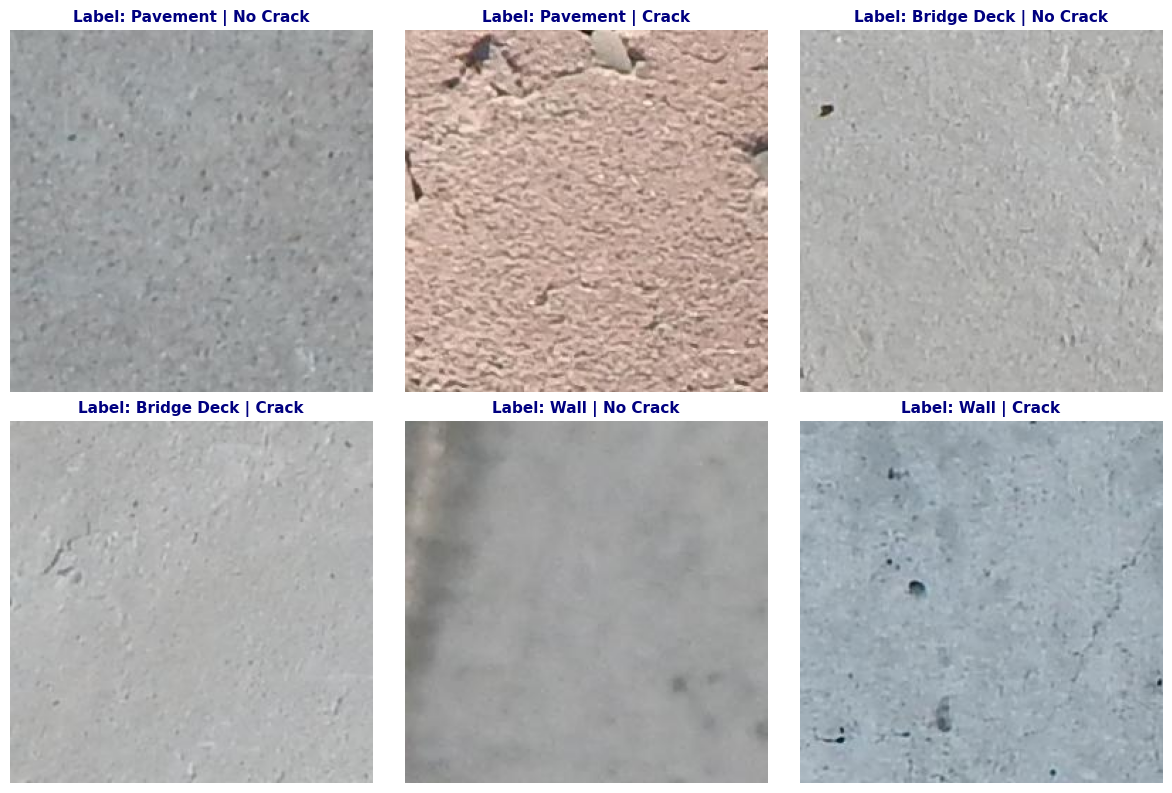


⚙️ Extracting Patch-Free 60-D Shi-Tomasi features (Parallel Enabled)...


100%|██████████| 56092/56092 [03:49<00:00, 243.92it/s]



--- Extracted Dataset Breakdown (6-Class) ---
 • Wall | Crack: 2000 images
 • Pavement | No Crack: 2000 images
 • Wall | No Crack: 2000 images
 • Bridge Deck | No Crack: 2000 images
 • Pavement | Crack: 2000 images
 • Bridge Deck | Crack: 2000 images

 🚀 PIPELINE FOR 2-CLASS (CONDITION) CLASSIFICATION (Split: 70/30)

---> SVM [2-Class (Condition)]
 • Overall Accuracy   : 57.06%
 • Macro Precision    : 0.5707
 • Macro Sensitivity  : 0.5706  (Sensitivity = Recall)
 • Macro F1-Score     : 0.5704

   --- Per-Class Performance Breakdown ---
   - Crack                | Precision: 0.5733 | Sensitivity/Recall: 0.5517 | F1: 0.5623
   - No Crack             | Precision: 0.5680 | Sensitivity/Recall: 0.5894 | F1: 0.5785

---> Random Forest [2-Class (Condition)]
 • Overall Accuracy   : 59.81%
 • Macro Precision    : 0.5983
 • Macro Sensitivity  : 0.5981  (Sensitivity = Recall)
 • Macro F1-Score     : 0.5978

   --- Per-Class Performance Breakdown ---
   - Crack                | Precision: 0.6032 |

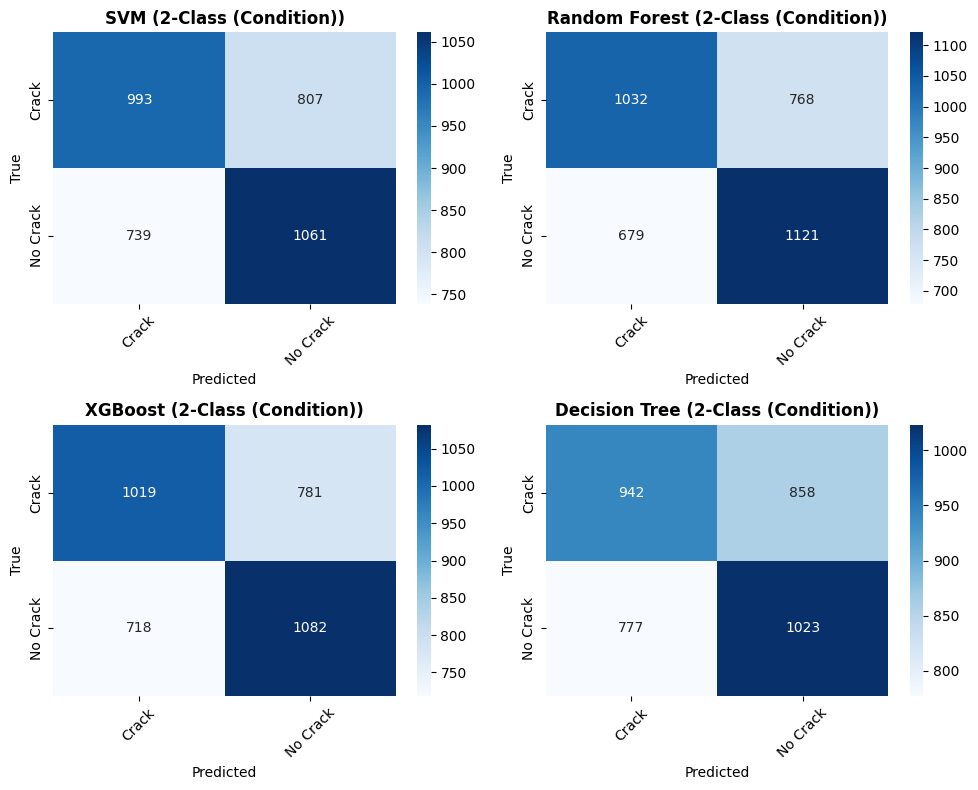


 🚀 PIPELINE FOR 3-CLASS (SURFACE STRUCTURE) CLASSIFICATION (Split: 70/30)

---> SVM [3-Class (Surface Structure)]
 • Overall Accuracy   : 65.28%
 • Macro Precision    : 0.6621
 • Macro Sensitivity  : 0.6528  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6556

   --- Per-Class Performance Breakdown ---
   - Bridge Deck          | Precision: 0.5424 | Sensitivity/Recall: 0.6283 | F1: 0.5822
   - Pavement             | Precision: 0.8392 | Sensitivity/Recall: 0.7742 | F1: 0.8054
   - Wall                 | Precision: 0.6047 | Sensitivity/Recall: 0.5558 | F1: 0.5792

---> Random Forest [3-Class (Surface Structure)]
 • Overall Accuracy   : 75.25%
 • Macro Precision    : 0.7528
 • Macro Sensitivity  : 0.7525  (Sensitivity = Recall)
 • Macro F1-Score     : 0.7527

   --- Per-Class Performance Breakdown ---
   - Bridge Deck          | Precision: 0.7029 | Sensitivity/Recall: 0.7058 | F1: 0.7044
   - Pavement             | Precision: 0.8354 | Sensitivity/Recall: 0.8292 | F1: 0.8323
   - Wall  

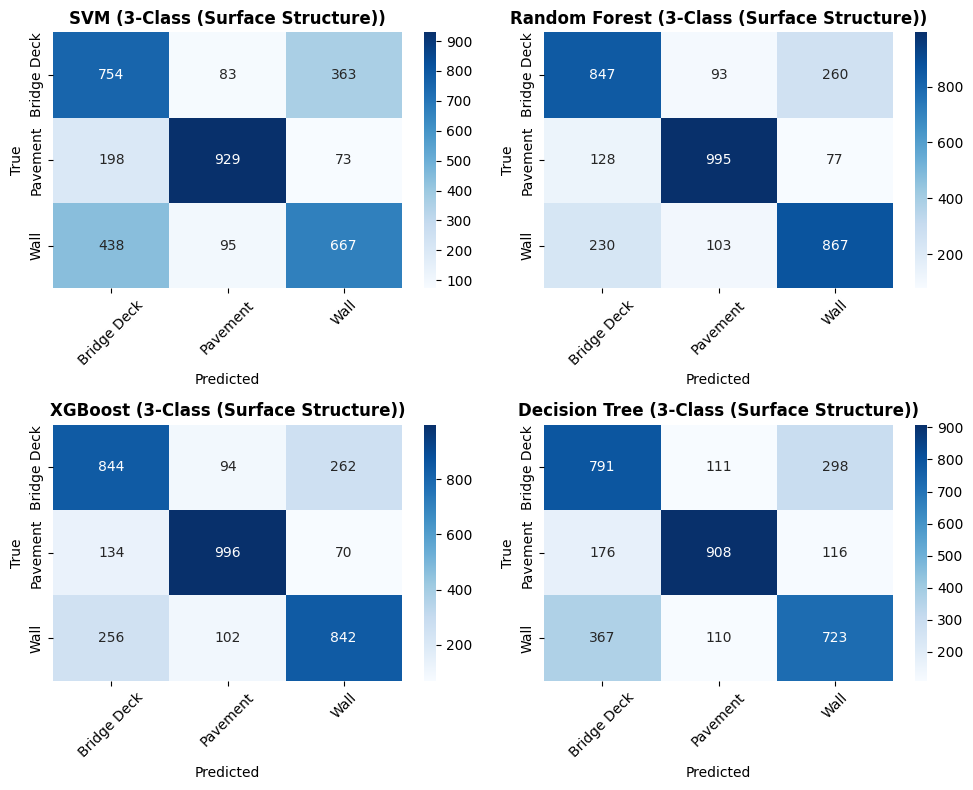


 🚀 PIPELINE FOR 6-CLASS (FINE-GRAINED) CLASSIFICATION (Split: 70/30)

---> SVM [6-Class (Fine-Grained)]
 • Overall Accuracy   : 38.08%
 • Macro Precision    : 0.3867
 • Macro Sensitivity  : 0.3808  (Sensitivity = Recall)
 • Macro F1-Score     : 0.3798

   --- Per-Class Performance Breakdown ---
   - Bridge Deck | Crack  | Precision: 0.3032 | Sensitivity/Recall: 0.3300 | F1: 0.3160
   - Bridge Deck | No Crack | Precision: 0.3322 | Sensitivity/Recall: 0.4833 | F1: 0.3938
   - Pavement | Crack     | Precision: 0.5168 | Sensitivity/Recall: 0.4883 | F1: 0.5021
   - Pavement | No Crack  | Precision: 0.4572 | Sensitivity/Recall: 0.4100 | F1: 0.4323
   - Wall | Crack         | Precision: 0.3739 | Sensitivity/Recall: 0.2967 | F1: 0.3309
   - Wall | No Crack      | Precision: 0.3367 | Sensitivity/Recall: 0.2767 | F1: 0.3038

---> Random Forest [6-Class (Fine-Grained)]
 • Overall Accuracy   : 44.39%
 • Macro Precision    : 0.4414
 • Macro Sensitivity  : 0.4439  (Sensitivity = Recall)
 • Macro F1

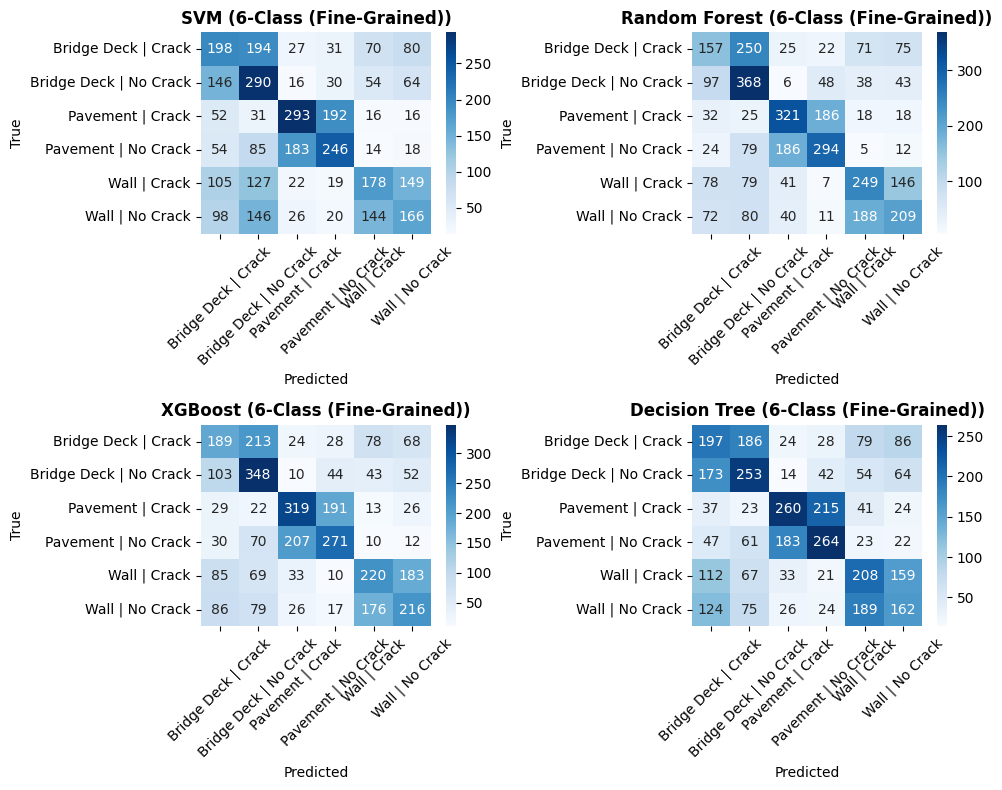


 📥 KAGGLE IMAGE UPLOADER & DETECTOR WIDGET


In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import io
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output
from joblib import Parallel, delayed

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, confusion_matrix
)

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# =====================================================================
# CONFIGURATION SETTINGS
# =====================================================================
TEST_SIZE = 0.30  # 70/30 Train/Test split
SAMPLES_PER_CLASS = 2000  # Sample size per class for training

# =====================================================================
# 1. PATCH-FREE (GLOBAL-ONLY) SHI-TOMASI FEATURE EXTRACTION
# =====================================================================
def extract_global_shitomasi_features(img_path, max_corners=20):
    """
    PATCH-FREE EXTRACTION: Runs directly on the full full-resolution image.
    Extracts top-20 global Shi-Tomasi corners [x1, y1, score1, ..., x20, y20, score20].
    
    Total Vector Dimension = 60 (20 corners * 3 attributes)
    """
    target_len = max_corners * 3
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None

    h, w = img.shape

    # Pre-processing: Smooth surface noise while preserving structural crack boundaries
    gray_prep = cv2.bilateralFilter(img, d=7, sigmaColor=50, sigmaSpace=50)

    # Calculate Shi-Tomasi Min Eigenvalue response map across the whole image
    corner_map = cv2.cornerMinEigenVal(gray_prep, blockSize=3, ksize=3)

    # Detect global corners (qualityLevel=0.001 ensures smooth surfaces still yield points)
    corners = cv2.goodFeaturesToTrack(
        gray_prep, 
        maxCorners=max_corners, 
        qualityLevel=0.001, 
        minDistance=10
    )

    vector = []
    if corners is not None:
        for pt in corners:
            x, y = pt.ravel()
            # Safe boundary clamping to prevent out-of-bounds indexing
            x_idx = min(int(round(x)), w - 1)
            y_idx = min(int(round(y)), h - 1)
            
            score = float(corner_map[y_idx, x_idx])
            vector.extend([float(x), float(y), score])

    # Zero-padding fallback if fewer than max_corners are found
    if len(vector) < target_len:
        vector.extend([0.0] * (target_len - len(vector)))
    else:
        vector = vector[:target_len]

    return np.array(vector, dtype=np.float32)

# =====================================================================
# 2. EXACT MATCH PARSER FOR SDNET DATASET
# =====================================================================
def parse_sdnet_labels(path):
    p = path.replace('\\', '/').lower()
    parts = p.split('/')
    
    leaf_folder = parts[-2] if len(parts) >= 2 else ""
    parent_folder = parts[-3] if len(parts) >= 3 else ""
    
    struct = None
    status = None

    if "non-cracked" in leaf_folder or "uncracked" in leaf_folder:
        status = "No Crack"
    elif "cracked" in leaf_folder:
        status = "Crack"

    if "deck" in parent_folder or "deck" in leaf_folder:
        struct = "Bridge Deck"
    elif "pavement" in parent_folder or "pavement" in leaf_folder:
        struct = "Pavement"
    elif "wall" in parent_folder or "wall" in leaf_folder:
        struct = "Wall"

    if struct is None or status is None:
        return None

    return status, struct, f"{struct} | {status}"

# Discover images
print("🔍 Discovering images in Kaggle directory...")
all_jpgs = []
for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            all_jpgs.append(os.path.join(root, f))

# =====================================================================
# 3. VISUALIZE REPRESENTATIVE SAMPLE IMAGE FOR EVERY DETECTED CLASS
# =====================================================================
print("\n🖼️ Displaying sample labeled images from dataset folders...")
class_samples = {}
for img_path in all_jpgs:
    parsed = parse_sdnet_labels(img_path)
    if parsed:
        l6 = parsed[2]
        if l6 not in class_samples:
            class_samples[l6] = img_path

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.ravel()

for idx, (label_name, sample_path) in enumerate(class_samples.items()):
    if idx < 6:
        sample_img = cv2.imread(sample_path)
        sample_img = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
        axes[idx].imshow(sample_img)
        axes[idx].set_title(f"Label: {label_name}", fontsize=11, fontweight='bold', color='navy')
        axes[idx].axis('off')

plt.tight_layout()
plt.show()

# =====================================================================
# 4. FAST PARALLEL FEATURE EXTRACTION (PATCH-FREE 60-D)
# =====================================================================
np.random.seed(42)
np.random.shuffle(all_jpgs)

def worker_process_image(img_path):
    parsed = parse_sdnet_labels(img_path)
    if parsed is None:
        return None
    feats = extract_global_shitomasi_features(img_path)
    if feats is None:
        return None
    return feats, parsed, img_path

print(f"\n⚙️ Extracting Patch-Free 60-D Shi-Tomasi features (Parallel Enabled)...")
results = Parallel(n_jobs=-1, batch_size=64)(
    delayed(worker_process_image)(img_path) for img_path in tqdm(all_jpgs)
)

X, y_2class, y_3class, y_6class, image_paths = [], [], [], [], []
class_counts = {}

for res in results:
    if res is None:
        continue
    feats, (l2, l3, l6), img_path = res
    if class_counts.get(l6, 0) >= SAMPLES_PER_CLASS:
        continue

    X.append(feats)
    y_2class.append(l2)
    y_3class.append(l3)
    y_6class.append(l6)
    image_paths.append(img_path)
    class_counts[l6] = class_counts.get(l6, 0) + 1

X = np.array(X, dtype=np.float32)
y_2class = np.array(y_2class)
y_3class = np.array(y_3class)
y_6class = np.array(y_6class)

print("\n--- Extracted Dataset Breakdown (6-Class) ---")
for k, v in class_counts.items():
    print(f" • {k}: {v} images")

# =====================================================================
# 5. PIPELINE TRAINER WITH PER-CLASS BREAKDOWN & MACRO METRICS
# =====================================================================
def train_and_eval_task(task_name, X_data, y_data, test_ratio=0.30):
    train_pct = int((1 - test_ratio) * 100)
    test_pct = int(test_ratio * 100)
    
    print("\n" + "="*70)
    print(f" 🚀 PIPELINE FOR {task_name.upper()} CLASSIFICATION (Split: {train_pct}/{test_pct})")
    print("="*70)

    le = LabelEncoder()
    y_encoded = le.fit_transform(y_data)

    X_train, X_test, y_train, y_test = train_test_split(
        X_data, y_encoded, test_size=test_ratio, random_state=42, stratify=y_encoded
    )

    xgb_clf = XGBClassifier(
        n_estimators=200, 
        learning_rate=0.08, 
        eval_metric='mlogloss', 
        random_state=42, 
        n_jobs=-1
    )

    models = {
        "SVM": make_pipeline(StandardScaler(), SVC(kernel='rbf', C=5.0, probability=True, random_state=42)),
        "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=200, max_depth=20, random_state=42, n_jobs=-1)),
        "XGBoost": make_pipeline(StandardScaler(), xgb_clf),
        "Decision Tree": make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=12, random_state=42))
    }

    trained = {}
    metrics = {}

    for name, model in models.items():
        model.fit(X_train, y_train)
        preds = model.predict(X_test)
        
        acc = accuracy_score(y_test, preds)
        macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
            y_test, preds, average='macro', zero_division=0
        )
        macro_sens = macro_r

        per_p, per_r, per_f1, _ = precision_recall_fscore_support(
            y_test, preds, average=None, zero_division=0
        )
        
        cm = confusion_matrix(y_test, preds)

        trained[name] = model
        metrics[name] = {
            "accuracy": acc, "precision": macro_p, "recall": macro_r, 
            "sensitivity": macro_sens, "f1": macro_f1, "cm": cm
        }

        print(f"\n---> {name} [{task_name}]")
        print(f" • Overall Accuracy   : {acc * 100:.2f}%")
        print(f" • Macro Precision    : {macro_p:.4f}")
        print(f" • Macro Sensitivity  : {macro_sens:.4f}  (Sensitivity = Recall)")
        print(f" • Macro F1-Score     : {macro_f1:.4f}\n")
        print("   --- Per-Class Performance Breakdown ---")
        for cls_idx, cls_name in enumerate(le.classes_):
            p_val = per_p[cls_idx]
            r_val = per_r[cls_idx]
            f_val = per_f1[cls_idx]
            print(f"   - {cls_name:<20} | Precision: {p_val:.4f} | Sensitivity/Recall: {r_val:.4f} | F1: {f_val:.4f}")

    # Plot Confusion Matrices
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    axes = axes.ravel()
    for i, (name, m_info) in enumerate(metrics.items()):
        sns.heatmap(m_info['cm'], annot=True, fmt='d', cmap='Blues',
                    xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[i])
        axes[i].set_title(f"{name} ({task_name})", fontweight='bold')
        axes[i].set_xlabel("Predicted")
        axes[i].set_ylabel("True")
        axes[i].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

    return trained, metrics, le

# Run training pipelines
models_2c, metrics_2c, le_2c = train_and_eval_task("2-Class (Condition)", X, y_2class, test_ratio=TEST_SIZE)
models_3c, metrics_3c, le_3c = train_and_eval_task("3-Class (Surface Structure)", X, y_3class, test_ratio=TEST_SIZE)
models_6c, metrics_6c, le_6c = train_and_eval_task("6-Class (Fine-Grained)", X, y_6class, test_ratio=TEST_SIZE)

# =====================================================================
# 6. KAGGLE UPLOADER WIDGET
# =====================================================================
def create_kaggle_uploader(output_folder="/kaggle/working/predictions"):
    os.makedirs(output_folder, exist_ok=True)
    
    upload_widget = widgets.FileUpload(
        accept='.jpg,.jpeg,.png',
        multiple=False,
        description='Upload Image'
    )
    output_area = widgets.Output()

    def on_file_upload(change):
        with output_area:
            clear_output()
            if not upload_widget.value:
                return
            
            uploaded_file = list(upload_widget.value.values())[0] if isinstance(upload_widget.value, dict) else upload_widget.value[0]
            fname = uploaded_file['name'] if isinstance(uploaded_file, dict) else uploaded_file.name
            content = uploaded_file['content'] if isinstance(uploaded_file, dict) else uploaded_file.content
            
            saved_img_path = os.path.join(output_folder, fname)
            with open(saved_img_path, "wb") as f:
                f.write(content)
            
            feats = extract_global_shitomasi_features(saved_img_path)
            if feats is None:
                print(f"❌ Error: Unable to extract features from uploaded image '{fname}'.")
                return

            print(f"\n=================================================================")
            print(f" 📥 ANALYSIS & STRUCTURE DETECTION FOR: {fname}")
            print(f"=================================================================\n")

            img_pil = Image.open(io.BytesIO(content))
            plt.figure(figsize=(4, 4))
            plt.imshow(img_pil)
            plt.title(f"Target Image: {fname}", fontsize=10, fontweight='bold')
            plt.axis('off')
            plt.show()

            primary_model = models_6c["XGBoost"]
            pred_code = primary_model.predict([feats])[0]
            pred_label = le_6c.inverse_transform([pred_code])[0]
            
            detected_surface, detected_condition = pred_label.split(" | ")

            print("🔍 STRUCTURE DETECTION RESULT:")
            print("-----------------------------------------------------------------")
            print(f" 🏛️ Detected Structure Surface : {detected_surface.upper()} DETECTED")
            print(f" ⚠️ Detected Structural Condition : {detected_condition.upper()}")
            print("-----------------------------------------------------------------\n")

            print("📊 MULTI-MODEL METRIC PERFORMANCE BREAKDOWN:")
            for m_name in models_6c.keys():
                p_2c = le_2c.inverse_transform([models_2c[m_name].predict([feats])[0]])[0]
                p_3c = le_3c.inverse_transform([models_3c[m_name].predict([feats])[0]])[0]
                p_6c = le_6c.inverse_transform([models_6c[m_name].predict([feats])[0]])[0]
                
                print(f"\n🔹 ALGORITHM: {m_name}")
                print(f"   • 2-Class Condition Output : {p_2c}")
                print(f"   • 3-Class Structure Output : {p_3c}")
                print(f"   • 6-Class Full Prediction  : {p_6c}")

            txt_save_path = os.path.join(output_folder, os.path.splitext(fname)[0] + "_report.txt")
            with open(txt_save_path, "w") as f:
                f.write(f"DETECTION REPORT FOR: {fname}\n")
                f.write(f"Structure Detected: {detected_surface}\n")
                f.write(f"Condition State: {detected_condition}\n")

            print(f"\n✅ Classified image report saved at: '{output_folder}'")
            print("=================================================================\n")

    upload_widget.observe(on_file_upload, names='value')
    
    print("\n=================================================================")
    print(" 📥 KAGGLE IMAGE UPLOADER & DETECTOR WIDGET")
    print("=================================================================")
    display(upload_widget)
    display(output_area)

create_kaggle_uploader()

 MSER feature vectors (without image grid)

🔍 Discovering images in Kaggle directory...

🖼️ Displaying sample labeled images from dataset folders...


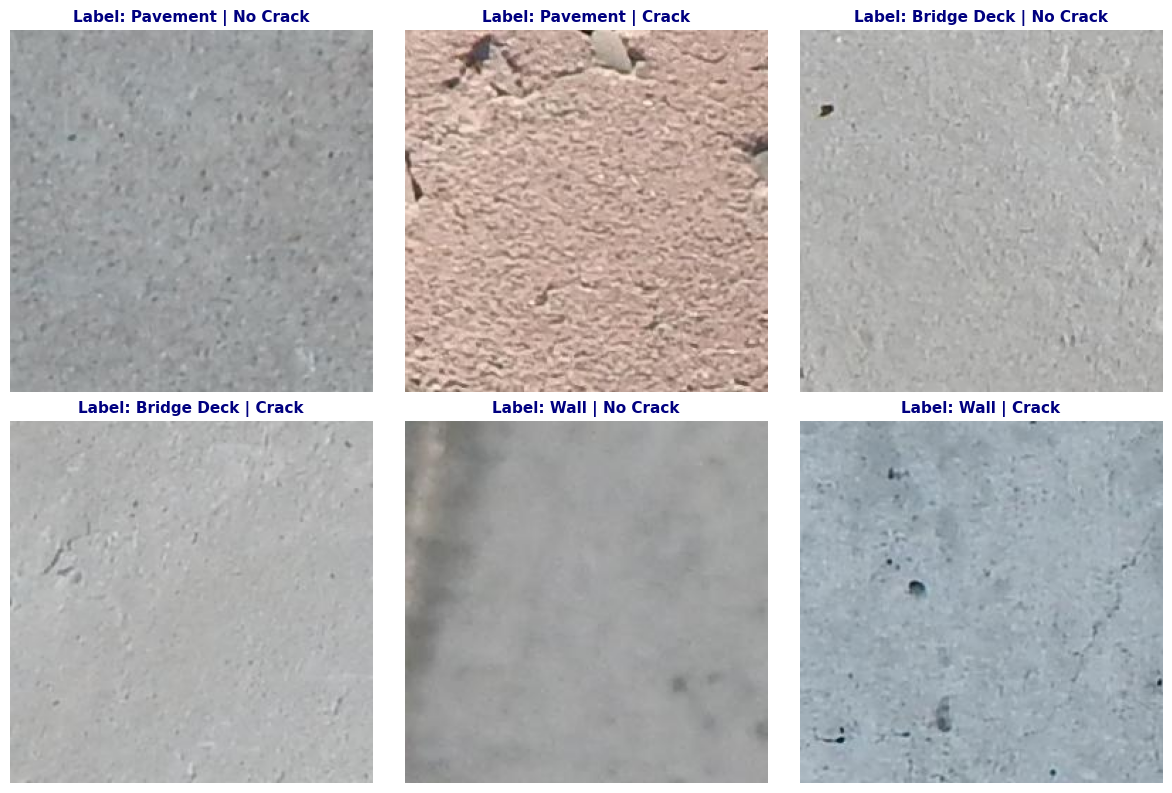


⚙️ Extracting 60-D Global MSER feature vectors (No Patching)...


100%|██████████| 56092/56092 [03:14<00:00, 288.84it/s] 



--- Extracted Dataset Breakdown (6-Class) ---
 • Wall | Crack: 2000 images
 • Pavement | No Crack: 2000 images
 • Wall | No Crack: 2000 images
 • Bridge Deck | No Crack: 2000 images
 • Pavement | Crack: 2000 images
 • Bridge Deck | Crack: 2000 images

 🚀 PIPELINE FOR 2-CLASS (CONDITION) CLASSIFICATION (Split: 70/30)

---> SVM [2-Class (Condition)]
 • Overall Accuracy   : 59.22%
 • Macro Precision    : 0.5939
 • Macro Sensitivity  : 0.5922  (Sensitivity = Recall)
 • Macro F1-Score     : 0.5904

   --- Per-Class Performance Breakdown ---
   - Crack                | Precision: 0.6065 | Sensitivity/Recall: 0.5250 | F1: 0.5628
   - No Crack             | Precision: 0.5813 | Sensitivity/Recall: 0.6594 | F1: 0.6179

---> Random Forest [2-Class (Condition)]
 • Overall Accuracy   : 61.39%
 • Macro Precision    : 0.6190
 • Macro Sensitivity  : 0.6139  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6097

   --- Per-Class Performance Breakdown ---
   - Crack                | Precision: 0.6438 |

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [07:08:19] WARNING: /__w/xgboost/xgboost/src/context.cc:53: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [07:08:19] WARNING: /__w/xgboost/xgboost/src/context.cc:207: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)



---> XGBoost [2-Class (Condition)]
 • Overall Accuracy   : 61.28%
 • Macro Precision    : 0.6150
 • Macro Sensitivity  : 0.6128  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6109

   --- Per-Class Performance Breakdown ---
   - Crack                | Precision: 0.6311 | Sensitivity/Recall: 0.5428 | F1: 0.5836
   - No Crack             | Precision: 0.5989 | Sensitivity/Recall: 0.6828 | F1: 0.6381

---> Decision Tree [2-Class (Condition)]
 • Overall Accuracy   : 57.42%
 • Macro Precision    : 0.5761
 • Macro Sensitivity  : 0.5742  (Sensitivity = Recall)
 • Macro F1-Score     : 0.5715

   --- Per-Class Performance Breakdown ---
   - Crack                | Precision: 0.5881 | Sensitivity/Recall: 0.4950 | F1: 0.5376
   - No Crack             | Precision: 0.5640 | Sensitivity/Recall: 0.6533 | F1: 0.6054


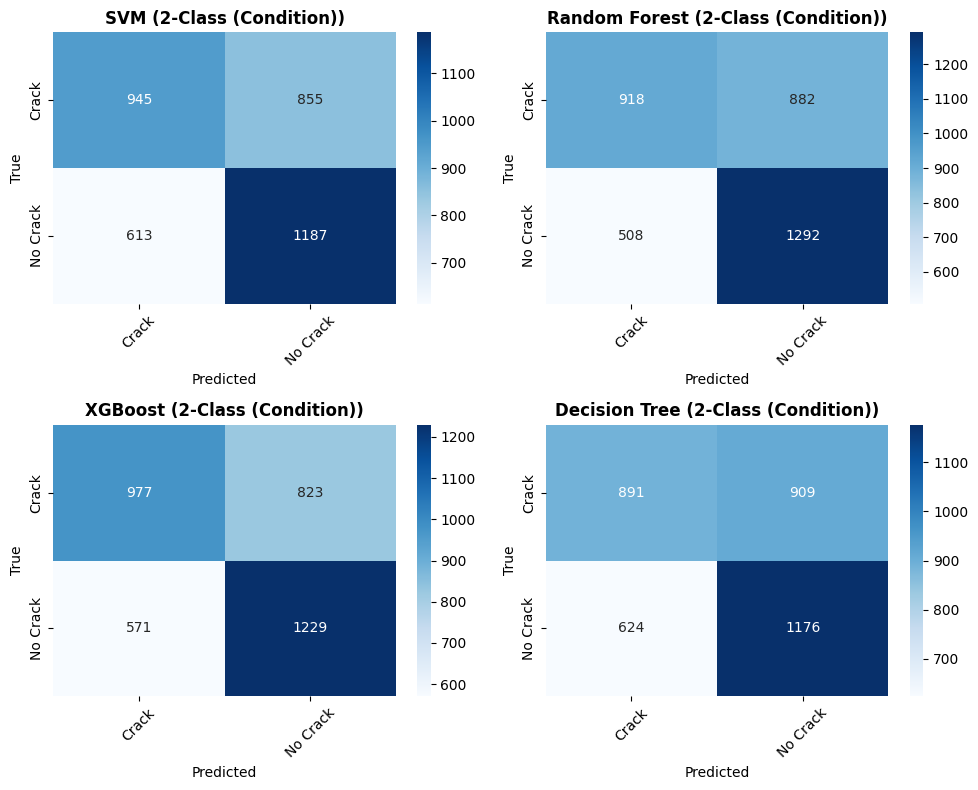


 🚀 PIPELINE FOR 3-CLASS (SURFACE STRUCTURE) CLASSIFICATION (Split: 70/30)

---> SVM [3-Class (Surface Structure)]
 • Overall Accuracy   : 60.75%
 • Macro Precision    : 0.6085
 • Macro Sensitivity  : 0.6075  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6072

   --- Per-Class Performance Breakdown ---
   - Bridge Deck          | Precision: 0.5383 | Sensitivity/Recall: 0.5917 | F1: 0.5637
   - Pavement             | Precision: 0.7426 | Sensitivity/Recall: 0.7333 | F1: 0.7379
   - Wall                 | Precision: 0.5447 | Sensitivity/Recall: 0.4975 | F1: 0.5200

---> Random Forest [3-Class (Surface Structure)]
 • Overall Accuracy   : 65.28%
 • Macro Precision    : 0.6513
 • Macro Sensitivity  : 0.6528  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6520

   --- Per-Class Performance Breakdown ---
   - Bridge Deck          | Precision: 0.6113 | Sensitivity/Recall: 0.6042 | F1: 0.6077
   - Pavement             | Precision: 0.7551 | Sensitivity/Recall: 0.7758 | F1: 0.7653
   - Wall  

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [07:09:03] WARNING: /__w/xgboost/xgboost/src/context.cc:53: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [07:09:03] WARNING: /__w/xgboost/xgboost/src/context.cc:207: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)



---> XGBoost [3-Class (Surface Structure)]
 • Overall Accuracy   : 65.08%
 • Macro Precision    : 0.6488
 • Macro Sensitivity  : 0.6508  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6497

   --- Per-Class Performance Breakdown ---
   - Bridge Deck          | Precision: 0.5903 | Sensitivity/Recall: 0.5908 | F1: 0.5906
   - Pavement             | Precision: 0.7663 | Sensitivity/Recall: 0.7925 | F1: 0.7792
   - Wall                 | Precision: 0.5898 | Sensitivity/Recall: 0.5692 | F1: 0.5793

---> Decision Tree [3-Class (Surface Structure)]
 • Overall Accuracy   : 57.22%
 • Macro Precision    : 0.5776
 • Macro Sensitivity  : 0.5722  (Sensitivity = Recall)
 • Macro F1-Score     : 0.5744

   --- Per-Class Performance Breakdown ---
   - Bridge Deck          | Precision: 0.5149 | Sensitivity/Recall: 0.5200 | F1: 0.5174
   - Pavement             | Precision: 0.7145 | Sensitivity/Recall: 0.6592 | F1: 0.6857
   - Wall                 | Precision: 0.5035 | Sensitivity/Recall: 0.5375 | F1: 0

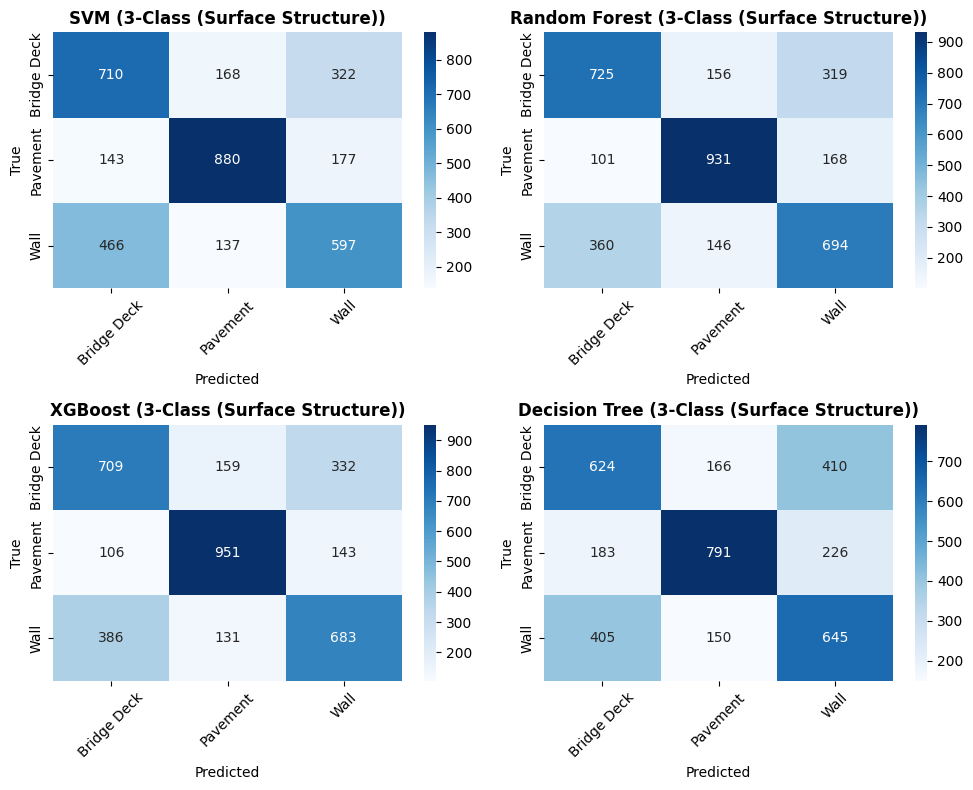


 🚀 PIPELINE FOR 6-CLASS (FINE-GRAINED) CLASSIFICATION (Split: 70/30)

---> SVM [6-Class (Fine-Grained)]
 • Overall Accuracy   : 38.31%
 • Macro Precision    : 0.3734
 • Macro Sensitivity  : 0.3831  (Sensitivity = Recall)
 • Macro F1-Score     : 0.3696

   --- Per-Class Performance Breakdown ---
   - Bridge Deck | Crack  | Precision: 0.3116 | Sensitivity/Recall: 0.1833 | F1: 0.2308
   - Bridge Deck | No Crack | Precision: 0.3600 | Sensitivity/Recall: 0.6000 | F1: 0.4500
   - Pavement | Crack     | Precision: 0.5540 | Sensitivity/Recall: 0.5983 | F1: 0.5753
   - Pavement | No Crack  | Precision: 0.4286 | Sensitivity/Recall: 0.4050 | F1: 0.4165
   - Wall | Crack         | Precision: 0.2566 | Sensitivity/Recall: 0.1950 | F1: 0.2216
   - Wall | No Crack      | Precision: 0.3299 | Sensitivity/Recall: 0.3167 | F1: 0.3231

---> Random Forest [6-Class (Fine-Grained)]
 • Overall Accuracy   : 41.31%
 • Macro Precision    : 0.4087
 • Macro Sensitivity  : 0.4131  (Sensitivity = Recall)
 • Macro F1

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [07:09:59] WARNING: /__w/xgboost/xgboost/src/context.cc:53: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [07:09:59] WARNING: /__w/xgboost/xgboost/src/context.cc:207: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)



---> XGBoost [6-Class (Fine-Grained)]
 • Overall Accuracy   : 40.97%
 • Macro Precision    : 0.4039
 • Macro Sensitivity  : 0.4097  (Sensitivity = Recall)
 • Macro F1-Score     : 0.4022

   --- Per-Class Performance Breakdown ---
   - Bridge Deck | Crack  | Precision: 0.3156 | Sensitivity/Recall: 0.2567 | F1: 0.2831
   - Bridge Deck | No Crack | Precision: 0.3888 | Sensitivity/Recall: 0.5683 | F1: 0.4617
   - Pavement | Crack     | Precision: 0.5785 | Sensitivity/Recall: 0.6267 | F1: 0.6016
   - Pavement | No Crack  | Precision: 0.5287 | Sensitivity/Recall: 0.4600 | F1: 0.4920
   - Wall | Crack         | Precision: 0.2876 | Sensitivity/Recall: 0.2200 | F1: 0.2493
   - Wall | No Crack      | Precision: 0.3245 | Sensitivity/Recall: 0.3267 | F1: 0.3256

---> Decision Tree [6-Class (Fine-Grained)]
 • Overall Accuracy   : 34.69%
 • Macro Precision    : 0.3401
 • Macro Sensitivity  : 0.3469  (Sensitivity = Recall)
 • Macro F1-Score     : 0.3394

   --- Per-Class Performance Breakdown ---
  

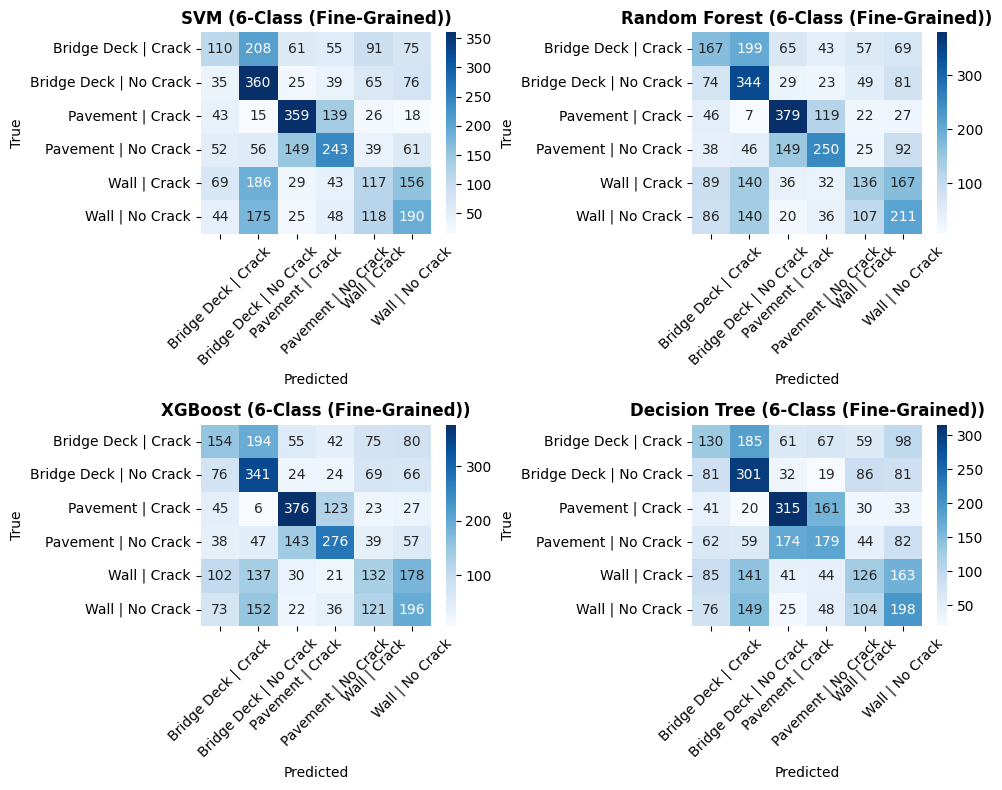


 📥 KAGGLE IMAGE UPLOADER & DETECTOR WIDGET


In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import io
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, confusion_matrix
)

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# =====================================================================
# CONFIGURATION SETTINGS
# =====================================================================
TEST_SIZE = 0.30  # 70/30 Train/Test split
SAMPLES_PER_CLASS = 2000  # Sample size per class for training

# =====================================================================
# 1. PURE GLOBAL MSER FEATURE EXTRACTION (NO PATCHES / NO GRIDS)
# =====================================================================
def extract_global_mser_features(img_path, max_regions=20):
    """
    Extracts top-20 MSER features directly from the full image (No spatial grid patching).
    Returns a fixed 60-dimensional vector: [x1, y1, area1, ..., x20, y20, area20]
    """
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None or img.size == 0:
        return None

    # Pre-processing: Smooth surface noise while preserving crack boundaries
    gray_prep = cv2.bilateralFilter(img, d=7, sigmaColor=50, sigmaSpace=50)

    # Initialize MSER detector
    mser = cv2.MSER_create(delta=2, min_area=8, max_area=5000)
    regions, _ = mser.detectRegions(gray_prep)

    vector = []
    if regions:
        # Sort regions by size (number of pixels) descending
        regions = sorted(regions, key=lambda p: len(p), reverse=True)[:max_regions]

        for p in regions:
            # Calculate centroid directly from region coordinate arrays
            # p shape is (N, 1, 2) or (N, 2)
            pts = p.reshape(-1, 2)
            cx = float(np.mean(pts[:, 0]))
            cy = float(np.mean(pts[:, 1]))
            area = float(len(pts))  # Pixel count area

            vector.extend([cx, cy, area])

    # Enforce exact vector dimension = 60 (20 regions * 3 parameters)
    target_len = max_regions * 3
    if len(vector) < target_len:
        vector.extend([0.0] * (target_len - len(vector)))  # Zero-padding
    else:
        vector = vector[:target_len]

    return np.array(vector, dtype=np.float32)

# =====================================================================
# 2. EXACT MATCH PARSER FOR SDNET DATASET
# =====================================================================
def parse_sdnet_labels(path):
    p = path.replace('\\', '/').lower()
    parts = p.split('/')
    
    leaf_folder = parts[-2] if len(parts) >= 2 else ""
    parent_folder = parts[-3] if len(parts) >= 3 else ""
    
    struct = None
    status = None

    if "non-cracked" in leaf_folder or "uncracked" in leaf_folder:
        status = "No Crack"
    elif "cracked" in leaf_folder:
        status = "Crack"

    if "deck" in parent_folder or "deck" in leaf_folder:
        struct = "Bridge Deck"
    elif "pavement" in parent_folder or "pavement" in leaf_folder:
        struct = "Pavement"
    elif "wall" in parent_folder or "wall" in leaf_folder:
        struct = "Wall"

    if struct is None or status is None:
        return None

    return status, struct, f"{struct} | {status}"

# Discover images
print("🔍 Discovering images in Kaggle directory...")
all_jpgs = []
for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            all_jpgs.append(os.path.join(root, f))

# =====================================================================
# 3. VISUALIZE REPRESENTATIVE SAMPLE IMAGE FOR EVERY DETECTED CLASS
# =====================================================================
print("\n🖼️ Displaying sample labeled images from dataset folders...")
class_samples = {}
for img_path in all_jpgs:
    parsed = parse_sdnet_labels(img_path)
    if parsed:
        l6 = parsed[2]
        if l6 not in class_samples:
            class_samples[l6] = img_path

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.ravel()

for idx, (label_name, sample_path) in enumerate(class_samples.items()):
    if idx < 6:
        sample_img = cv2.imread(sample_path)
        sample_img = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
        axes[idx].imshow(sample_img)
        axes[idx].set_title(f"Label: {label_name}", fontsize=11, fontweight='bold', color='navy')
        axes[idx].axis('off')

plt.tight_layout()
plt.show()

# =====================================================================
# 4. FEATURE EXTRACTION PIPELINE (PURE GLOBAL 60-D MSER)
# =====================================================================
X, y_2class, y_3class, y_6class, image_paths = [], [], [], [], []
class_counts = {}

np.random.seed(42)
np.random.shuffle(all_jpgs)

print(f"\n⚙️ Extracting 60-D Global MSER feature vectors (No Patching)...")
for img_path in tqdm(all_jpgs):
    parsed = parse_sdnet_labels(img_path)
    if parsed is None:
        continue
    
    l2, l3, l6 = parsed
    if class_counts.get(l6, 0) >= SAMPLES_PER_CLASS:
        continue

    feats = extract_global_mser_features(img_path)
    if feats is not None:
        X.append(feats)
        y_2class.append(l2)
        y_3class.append(l3)
        y_6class.append(l6)
        image_paths.append(img_path)
        class_counts[l6] = class_counts.get(l6, 0) + 1

X = np.array(X, dtype=np.float32)
y_2class = np.array(y_2class)
y_3class = np.array(y_3class)
y_6class = np.array(y_6class)

print("\n--- Extracted Dataset Breakdown (6-Class) ---")
for k, v in class_counts.items():
    print(f" • {k}: {v} images")

# =====================================================================
# 5. PIPELINE TRAINER WITH PER-CLASS BREAKDOWN & MACRO METRICS
# =====================================================================
def train_and_eval_task(task_name, X_data, y_data, test_ratio=0.30):
    train_pct = int((1 - test_ratio) * 100)
    test_pct = int(test_ratio * 100)
    
    print("\n" + "="*70)
    print(f" 🚀 PIPELINE FOR {task_name.upper()} CLASSIFICATION (Split: {train_pct}/{test_pct})")
    print("="*70)

    le = LabelEncoder()
    y_encoded = le.fit_transform(y_data)

    X_train, X_test, y_train, y_test = train_test_split(
        X_data, y_encoded, test_size=test_ratio, random_state=42, stratify=y_encoded
    )

    xgb_clf = XGBClassifier(
        n_estimators=200, 
        learning_rate=0.08, 
        eval_metric='mlogloss', 
        random_state=42, 
        tree_method='hist',
        device='cuda'
    )

    models = {
        "SVM": make_pipeline(StandardScaler(), SVC(kernel='rbf', C=5.0, probability=True, random_state=42)),
        "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=200, max_depth=20, random_state=42, n_jobs=-1)),
        "XGBoost": make_pipeline(StandardScaler(), xgb_clf),
        "Decision Tree": make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=12, random_state=42))
    }

    trained = {}
    metrics = {}

    for name, model in models.items():
        try:
            model.fit(X_train, y_train)
        except Exception:
            if name == "XGBoost":
                model.named_steps['xgbclassifier'].set_params(device='cpu')
                model.fit(X_train, y_train)

        preds = model.predict(X_test)
        acc = accuracy_score(y_test, preds)
        
        macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
            y_test, preds, average='macro', zero_division=0
        )
        macro_sens = macro_r

        per_p, per_r, per_f1, _ = precision_recall_fscore_support(
            y_test, preds, average=None, zero_division=0
        )
        
        cm = confusion_matrix(y_test, preds)

        trained[name] = model
        metrics[name] = {
            "accuracy": acc, "precision": macro_p, "recall": macro_r, 
            "sensitivity": macro_sens, "f1": macro_f1, "cm": cm
        }

        print(f"\n---> {name} [{task_name}]")
        print(f" • Overall Accuracy   : {acc * 100:.2f}%")
        print(f" • Macro Precision    : {macro_p:.4f}")
        print(f" • Macro Sensitivity  : {macro_sens:.4f}  (Sensitivity = Recall)")
        print(f" • Macro F1-Score     : {macro_f1:.4f}\n")
        print("   --- Per-Class Performance Breakdown ---")
        for cls_idx, cls_name in enumerate(le.classes_):
            p_val = per_p[cls_idx]
            r_val = per_r[cls_idx]
            f_val = per_f1[cls_idx]
            print(f"   - {cls_name:<20} | Precision: {p_val:.4f} | Sensitivity/Recall: {r_val:.4f} | F1: {f_val:.4f}")

    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    axes = axes.ravel()
    for i, (name, m_info) in enumerate(metrics.items()):
        sns.heatmap(m_info['cm'], annot=True, fmt='d', cmap='Blues',
                    xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[i])
        axes[i].set_title(f"{name} ({task_name})", fontweight='bold')
        axes[i].set_xlabel("Predicted")
        axes[i].set_ylabel("True")
        axes[i].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

    return trained, metrics, le

# Run training pipelines
models_2c, metrics_2c, le_2c = train_and_eval_task("2-Class (Condition)", X, y_2class, test_ratio=TEST_SIZE)
models_3c, metrics_3c, le_3c = train_and_eval_task("3-Class (Surface Structure)", X, y_3class, test_ratio=TEST_SIZE)
models_6c, metrics_6c, le_6c = train_and_eval_task("6-Class (Fine-Grained)", X, y_6class, test_ratio=TEST_SIZE)

# =====================================================================
# 6. KAGGLE UPLOADER WIDGET
# =====================================================================
def create_kaggle_uploader(output_folder="/kaggle/working/predictions"):
    os.makedirs(output_folder, exist_ok=True)
    
    upload_widget = widgets.FileUpload(
        accept='.jpg,.jpeg,.png',
        multiple=False,
        description='Upload Image'
    )
    output_area = widgets.Output()

    def on_file_upload(change):
        with output_area:
            clear_output()
            if not upload_widget.value:
                return
            
            uploaded_file = list(upload_widget.value.values())[0] if isinstance(upload_widget.value, dict) else upload_widget.value[0]
            fname = uploaded_file['name'] if isinstance(uploaded_file, dict) else uploaded_file.name
            content = uploaded_file['content'] if isinstance(uploaded_file, dict) else uploaded_file.content
            
            saved_img_path = os.path.join(output_folder, fname)
            with open(saved_img_path, "wb") as f:
                f.write(content)
            
            feats = extract_global_mser_features(saved_img_path)
            if feats is None:
                print(f"❌ Error: Unable to extract features from uploaded image '{fname}'.")
                return

            print(f"\n=================================================================")
            print(f" 📥 ANALYSIS & STRUCTURE DETECTION FOR: {fname}")
            print(f"=================================================================\n")

            img_pil = Image.open(io.BytesIO(content))
            plt.figure(figsize=(4, 4))
            plt.imshow(img_pil)
            plt.title(f"Target Image: {fname}", fontsize=10, fontweight='bold')
            plt.axis('off')
            plt.show()

            primary_model = models_6c["XGBoost"]
            pred_code = primary_model.predict([feats])[0]
            pred_label = le_6c.inverse_transform([pred_code])[0]
            
            detected_surface, detected_condition = pred_label.split(" | ")

            print("🔍 STRUCTURE DETECTION RESULT:")
            print("-----------------------------------------------------------------")
            print(f" 🏛️ Detected Structure Surface : {detected_surface.upper()} DETECTED")
            print(f" ⚠️ Detected Structural Condition : {detected_condition.upper()}")
            print("-----------------------------------------------------------------\n")

            print("📊 MULTI-MODEL METRIC PERFORMANCE BREAKDOWN:")
            for m_name in models_6c.keys():
                p_2c = le_2c.inverse_transform([models_2c[m_name].predict([feats])[0]])[0]
                p_3c = le_3c.inverse_transform([models_3c[m_name].predict([feats])[0]])[0]
                p_6c = le_6c.inverse_transform([models_6c[m_name].predict([feats])[0]])[0]
                
                print(f"\n🔹 ALGORITHM: {m_name}")
                print(f"   • 2-Class Condition Output : {p_2c}")
                print(f"   • 3-Class Structure Output : {p_3c}")
                print(f"   • 6-Class Full Prediction  : {p_6c}")

            txt_save_path = os.path.join(output_folder, os.path.splitext(fname)[0] + "_report.txt")
            with open(txt_save_path, "w") as f:
                f.write(f"DETECTION REPORT FOR: {fname}\n")
                f.write(f"Structure Detected: {detected_surface}\n")
                f.write(f"Condition State: {detected_condition}\n")

            print(f"\n✅ Classified image report saved at: '{output_folder}'")
            print("=================================================================\n")

    upload_widget.observe(on_file_upload, names='value')
    
    print("\n=================================================================")
    print(" 📥 KAGGLE IMAGE UPLOADER & DETECTOR WIDGET")
    print("=================================================================")
    display(upload_widget)
    display(output_area)

create_kaggle_uploader()

SURF without Patch

🔍 Discovering images in Kaggle directory...

🖼️ Displaying sample labeled images from dataset folders...


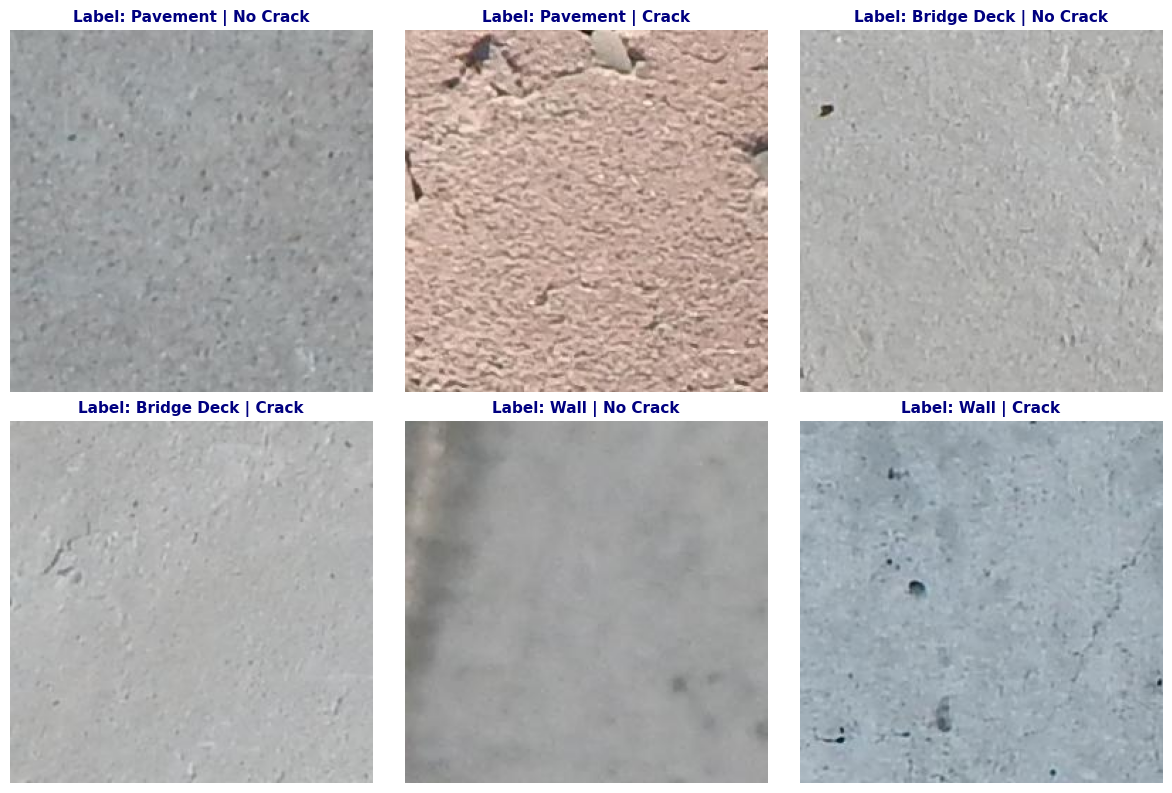


⚙️ Extracting 1280-D Global SURF feature vectors for dataset images...


100%|██████████| 56092/56092 [07:38<00:00, 122.34it/s]



--- Extracted Dataset Breakdown (6-Class) ---
 • Wall | Crack: 2000 images
 • Pavement | No Crack: 2000 images
 • Wall | No Crack: 2000 images
 • Bridge Deck | No Crack: 2000 images
 • Pavement | Crack: 2000 images
 • Bridge Deck | Crack: 2000 images

 🚀 PIPELINE FOR 2-CLASS (CONDITION) CLASSIFICATION (Split: 70/30)

---> SVM [2-Class (Condition)]
 • Overall Accuracy   : 67.25%
 • Macro Precision    : 0.6754
 • Macro Sensitivity  : 0.6725  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6711

    --- Per-Class Performance Breakdown ---
   - Crack                | Precision: 0.6981 | Sensitivity/Recall: 0.6078 | F1: 0.6498
   - No Crack             | Precision: 0.6527 | Sensitivity/Recall: 0.7372 | F1: 0.6924

---> Random Forest [2-Class (Condition)]
 • Overall Accuracy   : 69.00%
 • Macro Precision    : 0.7000
 • Macro Sensitivity  : 0.6900  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6861

    --- Per-Class Performance Breakdown ---
   - Crack                | Precision: 0.7446

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [13:45:56] WARNING: /__w/xgboost/xgboost/src/context.cc:53: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [13:45:56] WARNING: /__w/xgboost/xgboost/src/context.cc:207: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)



---> XGBoost [2-Class (Condition)]
 • Overall Accuracy   : 69.14%
 • Macro Precision    : 0.7003
 • Macro Sensitivity  : 0.6914  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6879

    --- Per-Class Performance Breakdown ---
   - Crack                | Precision: 0.7424 | Sensitivity/Recall: 0.5861 | F1: 0.6551
   - No Crack             | Precision: 0.6581 | Sensitivity/Recall: 0.7967 | F1: 0.7208

---> Decision Tree [2-Class (Condition)]
 • Overall Accuracy   : 60.97%
 • Macro Precision    : 0.6212
 • Macro Sensitivity  : 0.6097  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6003

    --- Per-Class Performance Breakdown ---
   - Crack                | Precision: 0.6584 | Sensitivity/Recall: 0.4561 | F1: 0.5389
   - No Crack             | Precision: 0.5839 | Sensitivity/Recall: 0.7633 | F1: 0.6617


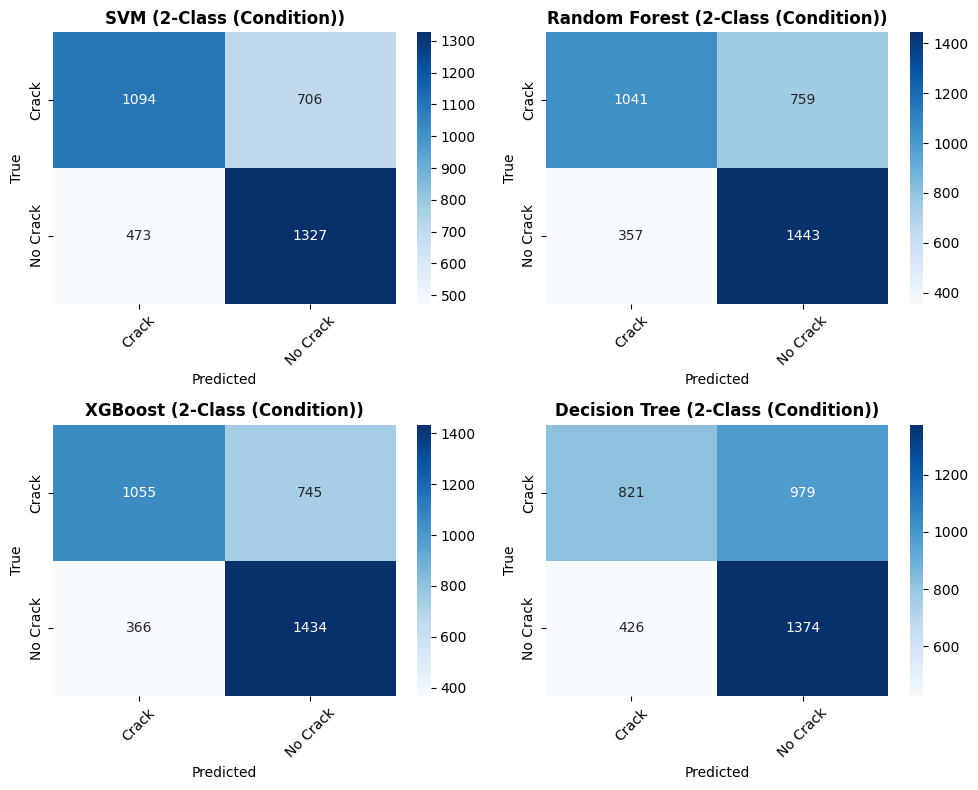


 🚀 PIPELINE FOR 3-CLASS (SURFACE STRUCTURE) CLASSIFICATION (Split: 70/30)

---> SVM [3-Class (Surface Structure)]
 • Overall Accuracy   : 77.06%
 • Macro Precision    : 0.7728
 • Macro Sensitivity  : 0.7706  (Sensitivity = Recall)
 • Macro F1-Score     : 0.7707

    --- Per-Class Performance Breakdown ---
   - Bridge Deck          | Precision: 0.6802 | Sensitivity/Recall: 0.7000 | F1: 0.6899
   - Pavement             | Precision: 0.8027 | Sensitivity/Recall: 0.8542 | F1: 0.8276
   - Wall                 | Precision: 0.8355 | Sensitivity/Recall: 0.7575 | F1: 0.7946

---> Random Forest [3-Class (Surface Structure)]
 • Overall Accuracy   : 76.28%
 • Macro Precision    : 0.7668
 • Macro Sensitivity  : 0.7628  (Sensitivity = Recall)
 • Macro F1-Score     : 0.7619

    --- Per-Class Performance Breakdown ---
   - Bridge Deck          | Precision: 0.6776 | Sensitivity/Recall: 0.6708 | F1: 0.6742
   - Pavement             | Precision: 0.7656 | Sensitivity/Recall: 0.8817 | F1: 0.8195
   - Wall

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [13:52:09] WARNING: /__w/xgboost/xgboost/src/context.cc:53: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [13:52:09] WARNING: /__w/xgboost/xgboost/src/context.cc:207: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)



---> XGBoost [3-Class (Surface Structure)]
 • Overall Accuracy   : 78.06%
 • Macro Precision    : 0.7830
 • Macro Sensitivity  : 0.7806  (Sensitivity = Recall)
 • Macro F1-Score     : 0.7808

    --- Per-Class Performance Breakdown ---
   - Bridge Deck          | Precision: 0.6900 | Sensitivity/Recall: 0.7142 | F1: 0.7019
   - Pavement             | Precision: 0.8127 | Sensitivity/Recall: 0.8608 | F1: 0.8361
   - Wall                 | Precision: 0.8464 | Sensitivity/Recall: 0.7667 | F1: 0.8045

---> Decision Tree [3-Class (Surface Structure)]
 • Overall Accuracy   : 64.03%
 • Macro Precision    : 0.6504
 • Macro Sensitivity  : 0.6403  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6430

    --- Per-Class Performance Breakdown ---
   - Bridge Deck          | Precision: 0.5326 | Sensitivity/Recall: 0.6267 | F1: 0.5758
   - Pavement             | Precision: 0.7310 | Sensitivity/Recall: 0.6817 | F1: 0.7055
   - Wall                 | Precision: 0.6876 | Sensitivity/Recall: 0.6125 | F1:

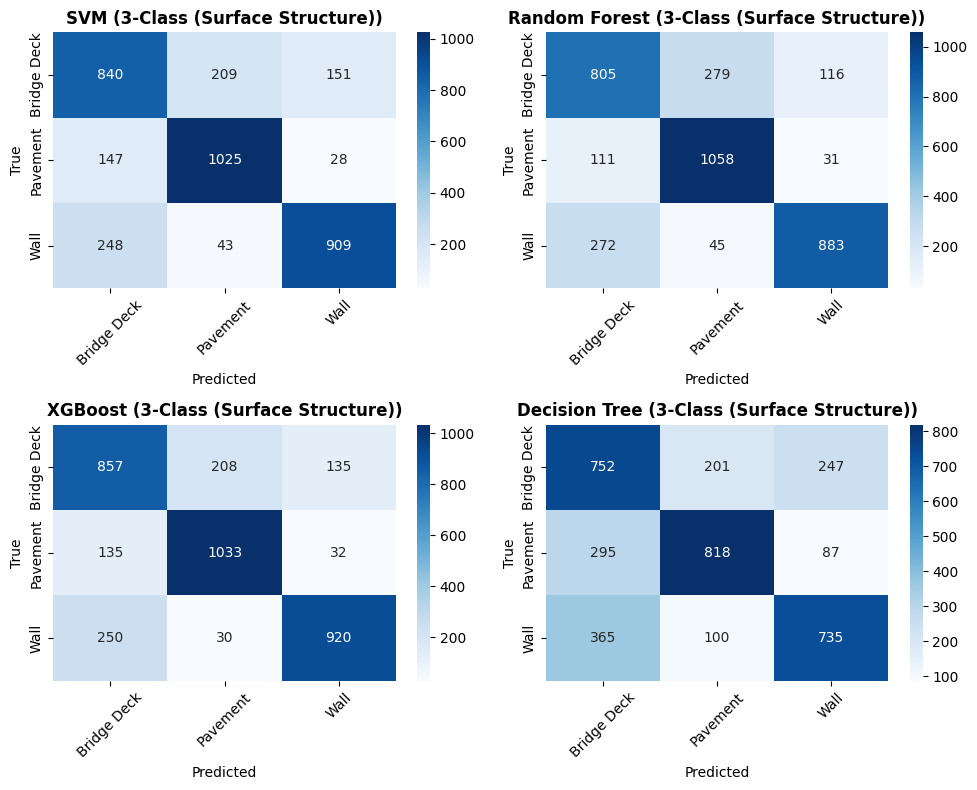


 🚀 PIPELINE FOR 6-CLASS (FINE-GRAINED) CLASSIFICATION (Split: 70/30)

---> SVM [6-Class (Fine-Grained)]
 • Overall Accuracy   : 52.64%
 • Macro Precision    : 0.5299
 • Macro Sensitivity  : 0.5264  (Sensitivity = Recall)
 • Macro F1-Score     : 0.5235

    --- Per-Class Performance Breakdown ---
   - Bridge Deck | Crack  | Precision: 0.4784 | Sensitivity/Recall: 0.3867 | F1: 0.4276
   - Bridge Deck | No Crack | Precision: 0.4333 | Sensitivity/Recall: 0.5850 | F1: 0.4979
   - Pavement | Crack     | Precision: 0.5674 | Sensitivity/Recall: 0.6100 | F1: 0.5880
   - Pavement | No Crack  | Precision: 0.5945 | Sensitivity/Recall: 0.6450 | F1: 0.6187
   - Wall | Crack         | Precision: 0.5420 | Sensitivity/Recall: 0.4083 | F1: 0.4658
   - Wall | No Crack      | Precision: 0.5637 | Sensitivity/Recall: 0.5233 | F1: 0.5428

---> Random Forest [6-Class (Fine-Grained)]
 • Overall Accuracy   : 51.75%
 • Macro Precision    : 0.5205
 • Macro Sensitivity  : 0.5175  (Sensitivity = Recall)
 • Macro F

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [14:01:34] WARNING: /__w/xgboost/xgboost/src/context.cc:53: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [14:01:34] WARNING: /__w/xgboost/xgboost/src/context.cc:207: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)



---> XGBoost [6-Class (Fine-Grained)]
 • Overall Accuracy   : 53.50%
 • Macro Precision    : 0.5404
 • Macro Sensitivity  : 0.5350  (Sensitivity = Recall)
 • Macro F1-Score     : 0.5334

    --- Per-Class Performance Breakdown ---
   - Bridge Deck | Crack  | Precision: 0.5420 | Sensitivity/Recall: 0.4517 | F1: 0.4927
   - Bridge Deck | No Crack | Precision: 0.4384 | Sensitivity/Recall: 0.6050 | F1: 0.5084
   - Pavement | Crack     | Precision: 0.5983 | Sensitivity/Recall: 0.5783 | F1: 0.5881
   - Pavement | No Crack  | Precision: 0.5853 | Sensitivity/Recall: 0.6517 | F1: 0.6167
   - Wall | Crack         | Precision: 0.5093 | Sensitivity/Recall: 0.4100 | F1: 0.4543
   - Wall | No Crack      | Precision: 0.5693 | Sensitivity/Recall: 0.5133 | F1: 0.5399

---> Decision Tree [6-Class (Fine-Grained)]
 • Overall Accuracy   : 38.28%
 • Macro Precision    : 0.3813
 • Macro Sensitivity  : 0.3828  (Sensitivity = Recall)
 • Macro F1-Score     : 0.3794

    --- Per-Class Performance Breakdown ---


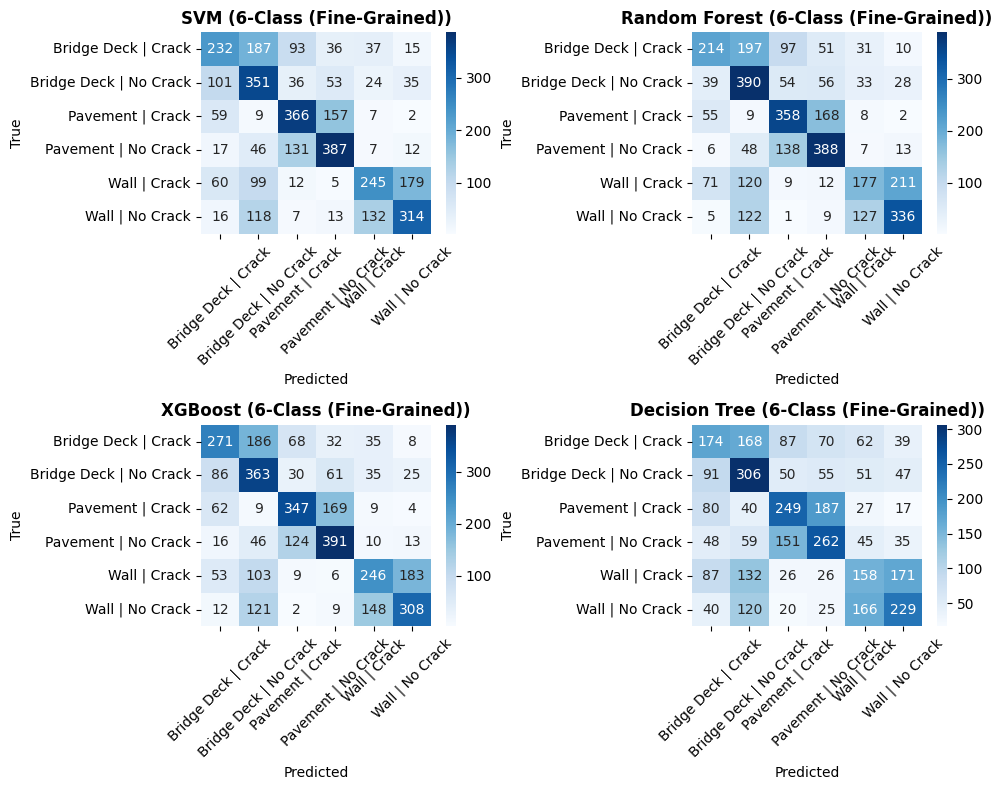


 📥 KAGGLE IMAGE UPLOADER & DETECTOR WIDGET


In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import io
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, confusion_matrix
)

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# =====================================================================
# CONFIGURATION SETTINGS
# =====================================================================
TEST_SIZE = 0.30       # 70/30 Train/Test split
SAMPLES_PER_CLASS = 2000  # Sample size per class for training
MAX_KEYPOINTS = 20     # Top 20 strongest keypoints
DESCRIPTOR_DIM = 64    # Standard SURF descriptor dimension (64 floats)
TARGET_DIM = MAX_KEYPOINTS * DESCRIPTOR_DIM  # Fixed 1280-D Feature Vector

# =====================================================================
# 1. GLOBAL SURF TOP-20 FEATURE EXTRACTION (NO PATCHES)
# =====================================================================
def extract_surf_global_features(img_path_or_array):
    """
    Extracts global SURF features across the full image without spatial patching.
    Sorts keypoints by Hessian response, selects top 20, and zero-pads if needed.
    Returns: Fixed 1280-D vector (20 keypoints * 64 descriptor dimensions).
    """
    if isinstance(img_path_or_array, str):
        img = cv2.imread(img_path_or_array, cv2.IMREAD_GRAYSCALE)
    else:
        img = img_path_or_array

    if img is None or img.size == 0:
        return np.zeros(TARGET_DIM, dtype=np.float32)

    # Noise reduction while preserving sharp crack boundaries
    prep_img = cv2.bilateralFilter(img, d=7, sigmaColor=50, sigmaSpace=50)

    descriptors = None
    keypoints = []

    # Attempt native SURF detection first
    try:
        surf = cv2.xfeatures2d.SURF_create(hessianThreshold=350, extended=False)
        keypoints, descriptors = surf.detectAndCompute(prep_img, None)
    except Exception:
        # Safety fallback to SIFT if environment lacks SURF module bindings
        sift = cv2.SIFT_create(nfeatures=MAX_KEYPOINTS)
        keypoints, descriptors = sift.detectAndCompute(prep_img, None)

    # Handle smooth images where 0 keypoints are found
    if descriptors is None or len(descriptors) == 0:
        return np.zeros(TARGET_DIM, dtype=np.float32)

    # Sort keypoints by response strength (strongest blobs/cracks first)
    if len(keypoints) == len(descriptors):
        sorted_pairs = sorted(zip(keypoints, descriptors), key=lambda x: x[0].response, reverse=True)
        descriptors = np.array([desc for _, desc in sorted_pairs])

    # Select Top 20 keypoints
    descriptors = descriptors[:MAX_KEYPOINTS]
    flat_vector = descriptors.flatten()

    # Zero-padding or truncation to ensure exact 1280-D vector length
    if len(flat_vector) < TARGET_DIM:
        flat_vector = np.pad(flat_vector, (0, TARGET_DIM - len(flat_vector)), mode='constant')
    else:
        flat_vector = flat_vector[:TARGET_DIM]

    return flat_vector.astype(np.float32)

# =====================================================================
# 2. EXACT MATCH PARSER FOR SDNET DATASET
# =====================================================================
def parse_sdnet_labels(path):
    p = path.replace('\\', '/').lower()
    parts = p.split('/')
    
    leaf_folder = parts[-2] if len(parts) >= 2 else ""
    parent_folder = parts[-3] if len(parts) >= 3 else ""
    
    struct = None
    status = None

    if "non-cracked" in leaf_folder or "uncracked" in leaf_folder:
        status = "No Crack"
    elif "cracked" in leaf_folder:
        status = "Crack"

    if "deck" in parent_folder or "deck" in leaf_folder:
        struct = "Bridge Deck"
    elif "pavement" in parent_folder or "pavement" in leaf_folder:
        struct = "Pavement"
    elif "wall" in parent_folder or "wall" in leaf_folder:
        struct = "Wall"

    if struct is None or status is None:
        return None

    return status, struct, f"{struct} | {status}"

# Discover images
print("🔍 Discovering images in Kaggle directory...")
all_jpgs = []
for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            all_jpgs.append(os.path.join(root, f))

# =====================================================================
# 3. VISUALIZE REPRESENTATIVE SAMPLE IMAGE FOR EVERY DETECTED CLASS
# =====================================================================
print("\n🖼️ Displaying sample labeled images from dataset folders...")
class_samples = {}
for img_path in all_jpgs:
    parsed = parse_sdnet_labels(img_path)
    if parsed:
        l6 = parsed[2]
        if l6 not in class_samples:
            class_samples[l6] = img_path

if class_samples:
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    axes = axes.ravel()

    for idx, (label_name, sample_path) in enumerate(class_samples.items()):
        if idx < 6:
            sample_img = cv2.imread(sample_path)
            sample_img = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
            axes[idx].imshow(sample_img)
            axes[idx].set_title(f"Label: {label_name}", fontsize=11, fontweight='bold', color='navy')
            axes[idx].axis('off')

    plt.tight_layout()
    plt.show()

# =====================================================================
# 4. FEATURE EXTRACTION PIPELINE
# =====================================================================
X, y_2class, y_3class, y_6class, image_paths = [], [], [], [], []
class_counts = {}

# Shuffle dataset paths to get random representative samples
np.random.seed(42)
np.random.shuffle(all_jpgs)

print(f"\n⚙️ Extracting 1280-D Global SURF feature vectors for dataset images...")
for img_path in tqdm(all_jpgs):
    parsed = parse_sdnet_labels(img_path)
    if parsed is None:
        continue
    
    l2, l3, l6 = parsed
    if class_counts.get(l6, 0) >= SAMPLES_PER_CLASS:
        continue

    feats = extract_surf_global_features(img_path)
    if feats is not None:
        X.append(feats)
        y_2class.append(l2)
        y_3class.append(l3)
        y_6class.append(l6)
        image_paths.append(img_path)
        class_counts[l6] = class_counts.get(l6, 0) + 1

X = np.array(X, dtype=np.float32)
y_2class = np.array(y_2class)
y_3class = np.array(y_3class)
y_6class = np.array(y_6class)

print("\n--- Extracted Dataset Breakdown (6-Class) ---")
for k, v in class_counts.items():
    print(f" • {k}: {v} images")

# Fallback synthetic data generator if no local dataset matches
if len(X) == 0:
    print("\n[!] No matching images found in /kaggle/input. Generating synthetic data for pipeline validation...")
    X = np.random.randn(600, TARGET_DIM).astype(np.float32)
    y_2class = np.random.choice(["Crack", "No Crack"], size=600)
    y_3class = np.random.choice(["Bridge Deck", "Pavement", "Wall"], size=600)
    y_6class = np.array([f"{s} | {c}" for s, c in zip(y_3class, y_2class)])

# =====================================================================
# 5. PIPELINE TRAINER WITH PER-CLASS BREAKDOWN & MACRO METRICS
# =====================================================================
def train_and_eval_task(task_name, X_data, y_data, test_ratio=0.30):
    train_pct = int((1 - test_ratio) * 100)
    test_pct = int(test_ratio * 100)
    
    print("\n" + "="*70)
    print(f" 🚀 PIPELINE FOR {task_name.upper()} CLASSIFICATION (Split: {train_pct}/{test_pct})")
    print("="*70)

    le = LabelEncoder()
    y_encoded = le.fit_transform(y_data)

    X_train, X_test, y_train, y_test = train_test_split(
        X_data, y_encoded, test_size=test_ratio, random_state=42, stratify=y_encoded
    )

    # Configure XGBoost GPU Classifier
    xgb_clf = XGBClassifier(
        n_estimators=200, 
        learning_rate=0.08, 
        eval_metric='mlogloss', 
        random_state=42, 
        tree_method='hist',
        device='cuda'
    )

    # Models wrapped with Standard Scalers inside Pipelines
    models = {
        "SVM": make_pipeline(StandardScaler(), SVC(kernel='rbf', C=5.0, probability=True, random_state=42)),
        "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=200, max_depth=20, random_state=42, n_jobs=-1)),
        "XGBoost": make_pipeline(StandardScaler(), xgb_clf),
        "Decision Tree": make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=12, random_state=42))
    }

    trained = {}
    metrics = {}

    for name, model in models.items():
        try:
            model.fit(X_train, y_train)
        except Exception:
            if name == "XGBoost":
                model.named_steps['xgbclassifier'].set_params(device='cpu')
                model.fit(X_train, y_train)

        preds = model.predict(X_test)
        
        acc = accuracy_score(y_test, preds)
        
        macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
            y_test, preds, average='macro', zero_division=0
        )
        macro_sens = macro_r

        per_p, per_r, per_f1, _ = precision_recall_fscore_support(
            y_test, preds, average=None, zero_division=0
        )
        
        cm = confusion_matrix(y_test, preds)

        trained[name] = model
        metrics[name] = {
            "accuracy": acc, "precision": macro_p, "recall": macro_r, 
            "sensitivity": macro_sens, "f1": macro_f1, "cm": cm
        }

        print(f"\n---> {name} [{task_name}]")
        print(f" • Overall Accuracy   : {acc * 100:.2f}%")
        print(f" • Macro Precision    : {macro_p:.4f}")
        print(f" • Macro Sensitivity  : {macro_sens:.4f}  (Sensitivity = Recall)")
        print(f" • Macro F1-Score     : {macro_f1:.4f}\n")
        print("    --- Per-Class Performance Breakdown ---")
        for cls_idx, cls_name in enumerate(le.classes_):
            p_val = per_p[cls_idx]
            r_val = per_r[cls_idx]
            f_val = per_f1[cls_idx]
            print(f"   - {cls_name:<20} | Precision: {p_val:.4f} | Sensitivity/Recall: {r_val:.4f} | F1: {f_val:.4f}")

    # Plot Confusion Matrices
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    axes = axes.ravel()
    for i, (name, m_info) in enumerate(metrics.items()):
        sns.heatmap(m_info['cm'], annot=True, fmt='d', cmap='Blues',
                    xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[i])
        axes[i].set_title(f"{name} ({task_name})", fontweight='bold')
        axes[i].set_xlabel("Predicted")
        axes[i].set_ylabel("True")
        axes[i].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

    return trained, metrics, le

# Run training pipelines
models_2c, metrics_2c, le_2c = train_and_eval_task("2-Class (Condition)", X, y_2class, test_ratio=TEST_SIZE)
models_3c, metrics_3c, le_3c = train_and_eval_task("3-Class (Surface Structure)", X, y_3class, test_ratio=TEST_SIZE)
models_6c, metrics_6c, le_6c = train_and_eval_task("6-Class (Fine-Grained)", X, y_6class, test_ratio=TEST_SIZE)

# =====================================================================
# 6. KAGGLE UPLOADER WIDGET
# =====================================================================
def create_kaggle_uploader(output_folder="/kaggle/working/predictions"):
    os.makedirs(output_folder, exist_ok=True)
    
    upload_widget = widgets.FileUpload(
        accept='.jpg,.jpeg,.png',
        multiple=False,
        description='Upload Image'
    )
    output_area = widgets.Output()

    def on_file_upload(change):
        with output_area:
            clear_output()
            if not upload_widget.value:
                return
            
            uploaded_file = list(upload_widget.value.values())[0] if isinstance(upload_widget.value, dict) else upload_widget.value[0]
            fname = uploaded_file['name'] if isinstance(uploaded_file, dict) else uploaded_file.name
            content = uploaded_file['content'] if isinstance(uploaded_file, dict) else uploaded_file.content
            
            saved_img_path = os.path.join(output_folder, fname)
            with open(saved_img_path, "wb") as f:
                f.write(content)
            
            feats = extract_surf_global_features(saved_img_path)
            if feats is None:
                print(f"❌ Error: Unable to extract SURF features from uploaded image '{fname}'.")
                return

            print(f"\n=================================================================")
            print(f" 📥 ANALYSIS & STRUCTURE DETECTION FOR: {fname}")
            print(f"=================================================================\n")

            img_pil = Image.open(io.BytesIO(content))
            plt.figure(figsize=(4, 4))
            plt.imshow(img_pil)
            plt.title(f"Target Image: {fname}", fontsize=10, fontweight='bold')
            plt.axis('off')
            plt.show()

            primary_model = models_6c["XGBoost"]
            pred_code = primary_model.predict([feats])[0]
            pred_label = le_6c.inverse_transform([pred_code])[0]
            
            if " | " in pred_label:
                detected_surface, detected_condition = pred_label.split(" | ")
            else:
                detected_surface, detected_condition = pred_label, "Unknown"

            print("🔍 STRUCTURE DETECTION RESULT:")
            print("-----------------------------------------------------------------")
            print(f" 🏛️ Detected Structure Surface : {detected_surface.upper()} DETECTED")
            print(f" ⚠️ Detected Structural Condition : {detected_condition.upper()}")
            print("-----------------------------------------------------------------\n")

            print("📊 MULTI-MODEL METRIC PERFORMANCE BREAKDOWN:")
            for m_name in models_6c.keys():
                p_2c = le_2c.inverse_transform([models_2c[m_name].predict([feats])[0]])[0]
                p_3c = le_3c.inverse_transform([models_3c[m_name].predict([feats])[0]])[0]
                p_6c = le_6c.inverse_transform([models_6c[m_name].predict([feats])[0]])[0]
                
                print(f"\n🔹 ALGORITHM: {m_name}")
                print(f"   • 2-Class Condition Output : {p_2c}")
                print(f"   • 3-Class Structure Output : {p_3c}")
                print(f"   • 6-Class Full Prediction  : {p_6c}")

            txt_save_path = os.path.join(output_folder, os.path.splitext(fname)[0] + "_report.txt")
            with open(txt_save_path, "w") as f:
                f.write(f"DETECTION REPORT FOR: {fname}\n")
                f.write(f"Structure Detected: {detected_surface}\n")
                f.write(f"Condition State: {detected_condition}\n")

            print(f"\n✅ Classified image report saved at: '{output_folder}'")
            print("=================================================================\n")

    upload_widget.observe(on_file_upload, names='value')
    
    print("\n=================================================================")
    print(" 📥 KAGGLE IMAGE UPLOADER & DETECTOR WIDGET")
    print("=================================================================")
    display(upload_widget)
    display(output_area)

create_kaggle_uploader()

BRISK features (without Grid)

🔍 Discovering images in Kaggle directory...

🖼️ Displaying sample labeled images from dataset folders...


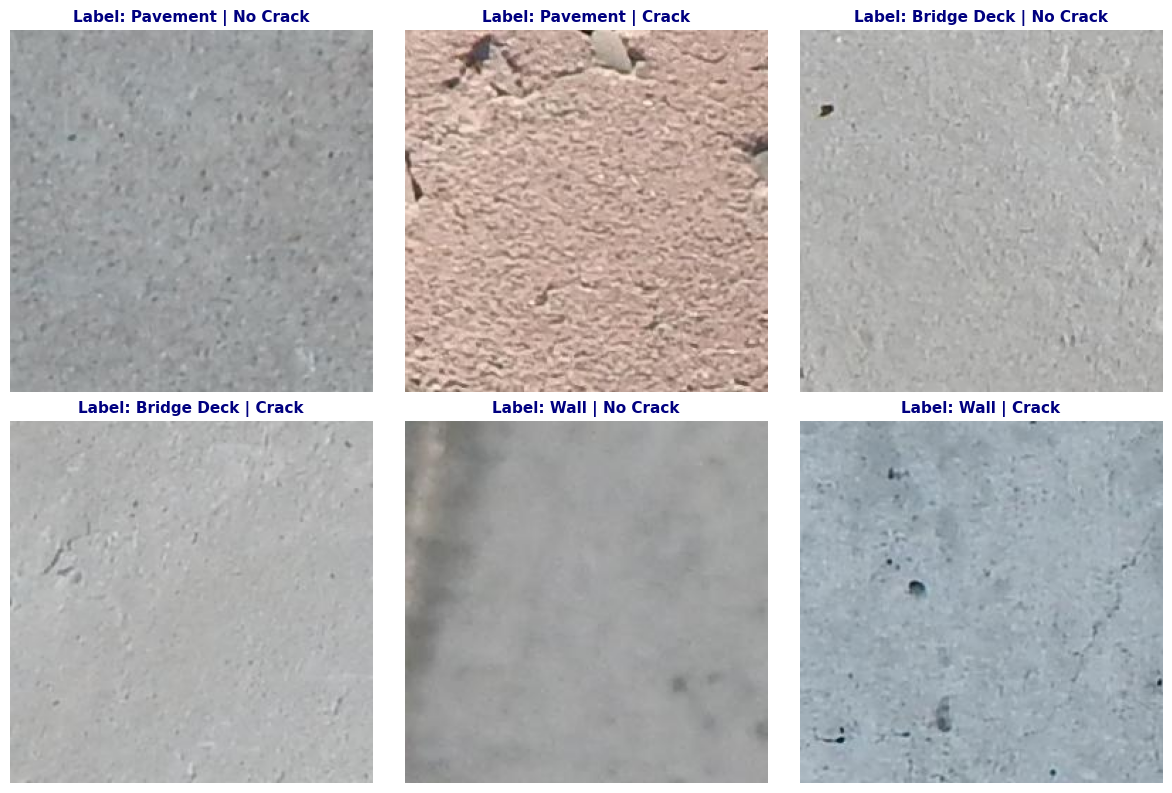


⚙️ Extracting 1280-D Global BRISK feature vectors for dataset images...


100%|██████████| 56092/56092 [13:28<00:00, 69.35it/s] 



--- Extracted Dataset Breakdown (6-Class) ---
 • Wall | Crack: 2000 images
 • Pavement | No Crack: 2000 images
 • Wall | No Crack: 2000 images
 • Bridge Deck | No Crack: 2000 images
 • Pavement | Crack: 2000 images
 • Bridge Deck | Crack: 2000 images

 🚀 PIPELINE FOR 2-CLASS (CONDITION) CLASSIFICATION (Split: 70/30)

---> SVM [2-Class (Condition)]
 • Overall Accuracy   : 57.17%
 • Macro Precision    : 0.5759
 • Macro Sensitivity  : 0.5717  (Sensitivity = Recall)
 • Macro F1-Score     : 0.5656

    --- Per-Class Performance Breakdown ---
   - Crack                | Precision: 0.5939 | Sensitivity/Recall: 0.4533 | F1: 0.5142
   - No Crack             | Precision: 0.5580 | Sensitivity/Recall: 0.6900 | F1: 0.6170

---> Random Forest [2-Class (Condition)]
 • Overall Accuracy   : 59.28%
 • Macro Precision    : 0.5945
 • Macro Sensitivity  : 0.5928  (Sensitivity = Recall)
 • Macro F1-Score     : 0.5910

    --- Per-Class Performance Breakdown ---
   - Crack                | Precision: 0.6071

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [16:56:09] WARNING: /__w/xgboost/xgboost/src/context.cc:53: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [16:56:09] WARNING: /__w/xgboost/xgboost/src/context.cc:207: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)



---> XGBoost [2-Class (Condition)]
 • Overall Accuracy   : 59.11%
 • Macro Precision    : 0.5936
 • Macro Sensitivity  : 0.5911  (Sensitivity = Recall)
 • Macro F1-Score     : 0.5884

    --- Per-Class Performance Breakdown ---
   - Crack                | Precision: 0.6089 | Sensitivity/Recall: 0.5094 | F1: 0.5547
   - No Crack             | Precision: 0.5783 | Sensitivity/Recall: 0.6728 | F1: 0.6220

---> Decision Tree [2-Class (Condition)]
 • Overall Accuracy   : 54.33%
 • Macro Precision    : 0.5445
 • Macro Sensitivity  : 0.5433  (Sensitivity = Recall)
 • Macro F1-Score     : 0.5403

    --- Per-Class Performance Breakdown ---
   - Crack                | Precision: 0.5518 | Sensitivity/Recall: 0.4617 | F1: 0.5027
   - No Crack             | Precision: 0.5372 | Sensitivity/Recall: 0.6250 | F1: 0.5778


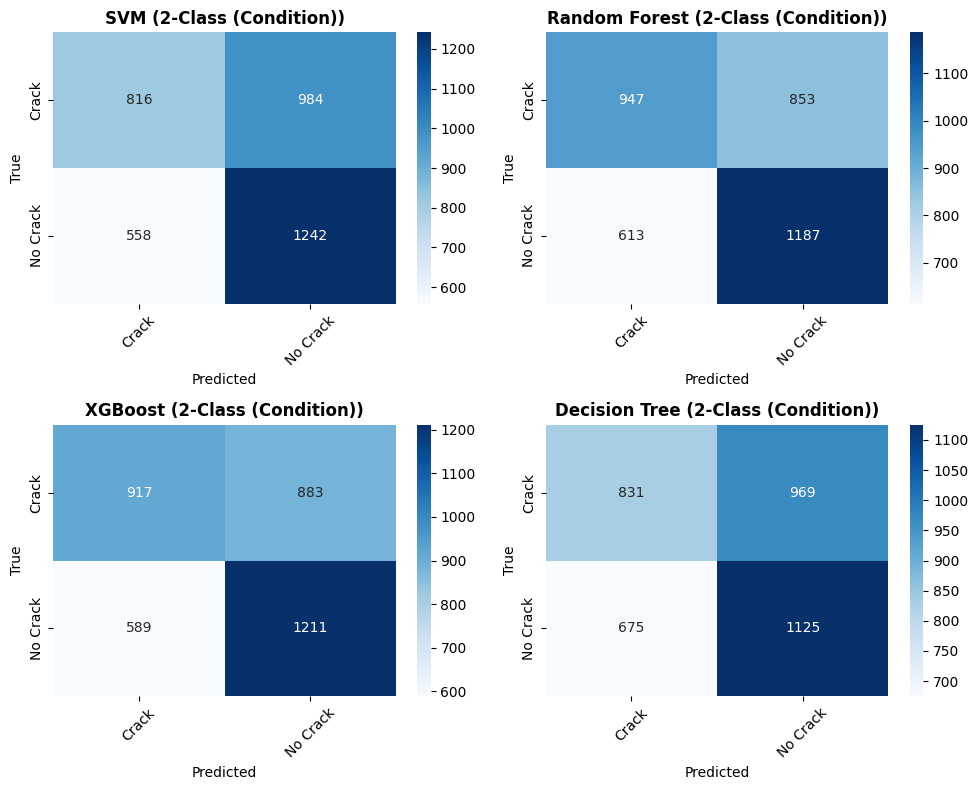


 🚀 PIPELINE FOR 3-CLASS (SURFACE STRUCTURE) CLASSIFICATION (Split: 70/30)

---> SVM [3-Class (Surface Structure)]
 • Overall Accuracy   : 66.39%
 • Macro Precision    : 0.6732
 • Macro Sensitivity  : 0.6639  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6622

    --- Per-Class Performance Breakdown ---
   - Bridge Deck          | Precision: 0.5719 | Sensitivity/Recall: 0.7292 | F1: 0.6410
   - Pavement             | Precision: 0.8056 | Sensitivity/Recall: 0.7633 | F1: 0.7839
   - Wall                 | Precision: 0.6420 | Sensitivity/Recall: 0.4992 | F1: 0.5617

---> Random Forest [3-Class (Surface Structure)]
 • Overall Accuracy   : 64.03%
 • Macro Precision    : 0.6372
 • Macro Sensitivity  : 0.6403  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6369

    --- Per-Class Performance Breakdown ---
   - Bridge Deck          | Precision: 0.5986 | Sensitivity/Recall: 0.6650 | F1: 0.6301
   - Pavement             | Precision: 0.7368 | Sensitivity/Recall: 0.7675 | F1: 0.7518
   - Wall

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [17:04:46] WARNING: /__w/xgboost/xgboost/src/context.cc:53: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [17:04:46] WARNING: /__w/xgboost/xgboost/src/context.cc:207: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)



---> XGBoost [3-Class (Surface Structure)]
 • Overall Accuracy   : 66.47%
 • Macro Precision    : 0.6686
 • Macro Sensitivity  : 0.6647  (Sensitivity = Recall)
 • Macro F1-Score     : 0.6628

    --- Per-Class Performance Breakdown ---
   - Bridge Deck          | Precision: 0.5827 | Sensitivity/Recall: 0.6958 | F1: 0.6343
   - Pavement             | Precision: 0.7794 | Sensitivity/Recall: 0.7800 | F1: 0.7797
   - Wall                 | Precision: 0.6439 | Sensitivity/Recall: 0.5183 | F1: 0.5743

---> Decision Tree [3-Class (Surface Structure)]
 • Overall Accuracy   : 55.69%
 • Macro Precision    : 0.5615
 • Macro Sensitivity  : 0.5569  (Sensitivity = Recall)
 • Macro F1-Score     : 0.5525

    --- Per-Class Performance Breakdown ---
   - Bridge Deck          | Precision: 0.5035 | Sensitivity/Recall: 0.6675 | F1: 0.5740
   - Pavement             | Precision: 0.7027 | Sensitivity/Recall: 0.6342 | F1: 0.6667
   - Wall                 | Precision: 0.4784 | Sensitivity/Recall: 0.3692 | F1:

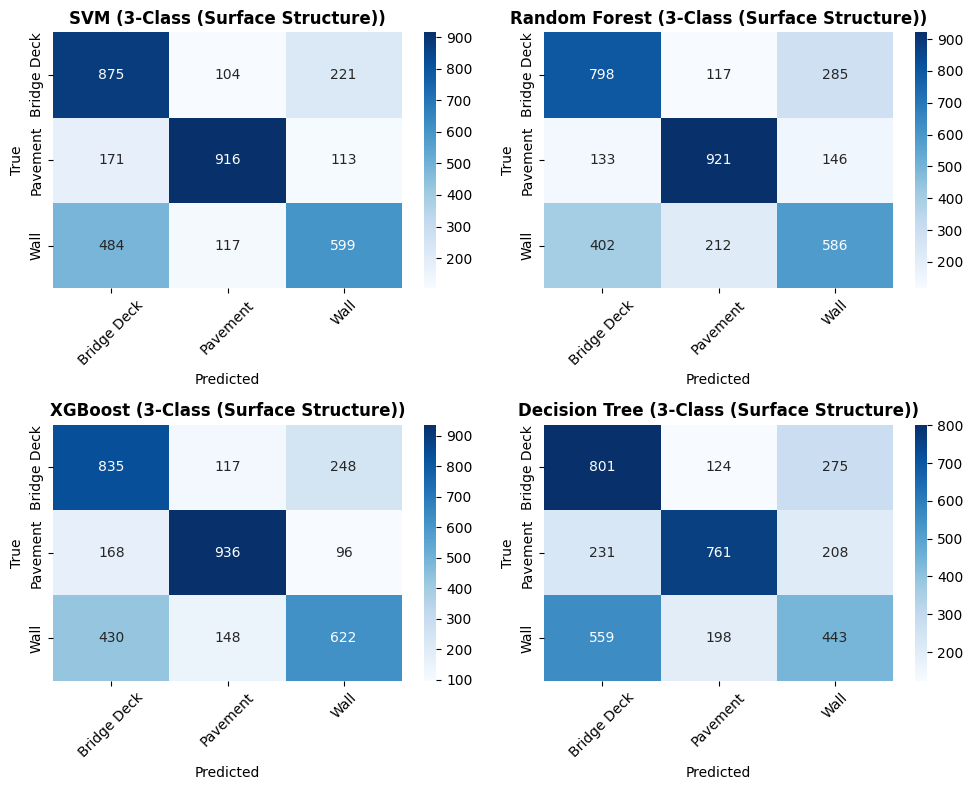


 🚀 PIPELINE FOR 6-CLASS (FINE-GRAINED) CLASSIFICATION (Split: 70/30)

---> SVM [6-Class (Fine-Grained)]
 • Overall Accuracy   : 39.19%
 • Macro Precision    : 0.3977
 • Macro Sensitivity  : 0.3919  (Sensitivity = Recall)
 • Macro F1-Score     : 0.3767

    --- Per-Class Performance Breakdown ---
   - Bridge Deck | Crack  | Precision: 0.3055 | Sensitivity/Recall: 0.1583 | F1: 0.2086
   - Bridge Deck | No Crack | Precision: 0.3185 | Sensitivity/Recall: 0.6800 | F1: 0.4338
   - Pavement | Crack     | Precision: 0.5371 | Sensitivity/Recall: 0.5550 | F1: 0.5459
   - Pavement | No Crack  | Precision: 0.4812 | Sensitivity/Recall: 0.4267 | F1: 0.4523
   - Wall | Crack         | Precision: 0.3446 | Sensitivity/Recall: 0.2383 | F1: 0.2818
   - Wall | No Crack      | Precision: 0.3991 | Sensitivity/Recall: 0.2933 | F1: 0.3381

---> Random Forest [6-Class (Fine-Grained)]
 • Overall Accuracy   : 38.94%
 • Macro Precision    : 0.3828
 • Macro Sensitivity  : 0.3894  (Sensitivity = Recall)
 • Macro F

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [17:18:01] WARNING: /__w/xgboost/xgboost/src/context.cc:53: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [17:18:01] WARNING: /__w/xgboost/xgboost/src/context.cc:207: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)



---> XGBoost [6-Class (Fine-Grained)]
 • Overall Accuracy   : 41.25%
 • Macro Precision    : 0.4112
 • Macro Sensitivity  : 0.4125  (Sensitivity = Recall)
 • Macro F1-Score     : 0.3982

    --- Per-Class Performance Breakdown ---
   - Bridge Deck | Crack  | Precision: 0.3009 | Sensitivity/Recall: 0.1600 | F1: 0.2089
   - Bridge Deck | No Crack | Precision: 0.3400 | Sensitivity/Recall: 0.6517 | F1: 0.4469
   - Pavement | Crack     | Precision: 0.5673 | Sensitivity/Recall: 0.5833 | F1: 0.5752
   - Pavement | No Crack  | Precision: 0.4966 | Sensitivity/Recall: 0.4883 | F1: 0.4924
   - Wall | Crack         | Precision: 0.3318 | Sensitivity/Recall: 0.2400 | F1: 0.2785
   - Wall | No Crack      | Precision: 0.4306 | Sensitivity/Recall: 0.3517 | F1: 0.3872

---> Decision Tree [6-Class (Fine-Grained)]
 • Overall Accuracy   : 31.53%
 • Macro Precision    : 0.3060
 • Macro Sensitivity  : 0.3153  (Sensitivity = Recall)
 • Macro F1-Score     : 0.2954

    --- Per-Class Performance Breakdown ---


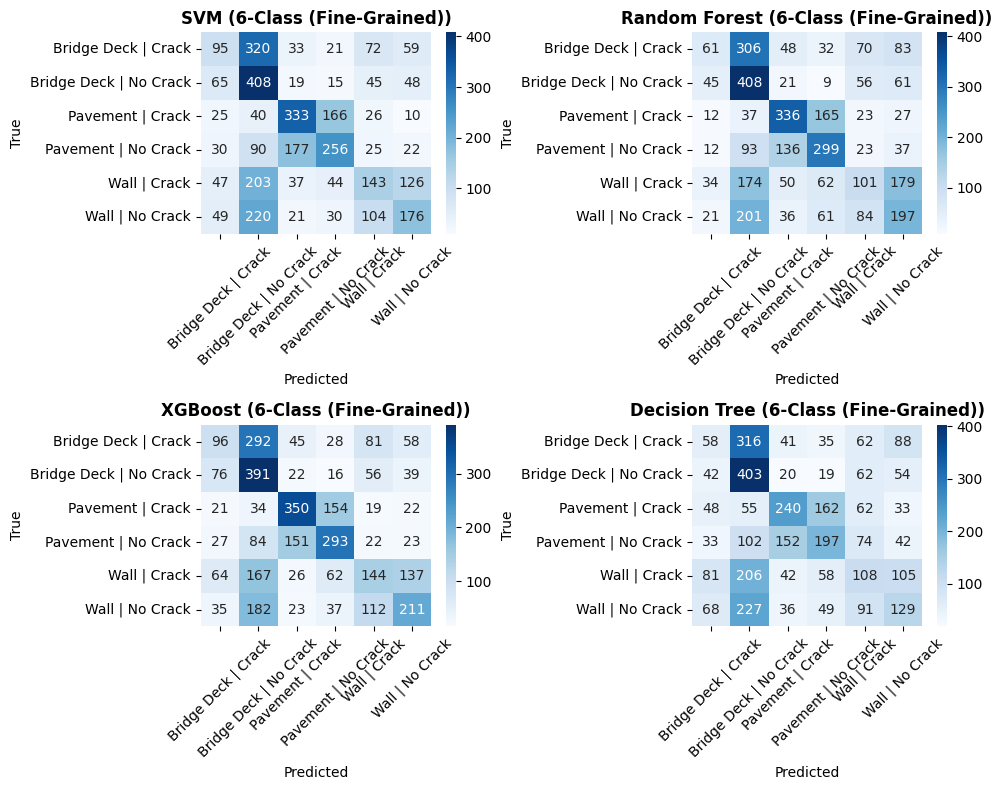


 📥 KAGGLE IMAGE UPLOADER & DETECTOR WIDGET


In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import io
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, confusion_matrix
)

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# =====================================================================
# CONFIGURATION SETTINGS
# =====================================================================
TEST_SIZE = 0.30       # 70/30 Train/Test split
SAMPLES_PER_CLASS = 2000  # Sample size per class for training
MAX_KEYPOINTS = 20     # Top 20 strongest keypoints
DESCRIPTOR_DIM = 64    # Standard BRISK descriptor dimension (64 bytes / 512 bits)
TARGET_DIM = MAX_KEYPOINTS * DESCRIPTOR_DIM  # Fixed 1280-D Feature Vector

# =====================================================================
# 1. GLOBAL BRISK TOP-20 FEATURE EXTRACTION (NO PATCHES)
# =====================================================================
def extract_brisk_global_features(img_path_or_array):
    """
    Extracts global BRISK features across the full image without spatial patching.
    Sorts keypoints by response strength, selects top 20, and zero-pads if needed.
    Returns: Fixed 1280-D vector (20 keypoints * 64 descriptor dimensions).
    """
    if isinstance(img_path_or_array, str):
        img = cv2.imread(img_path_or_array, cv2.IMREAD_GRAYSCALE)
    else:
        img = img_path_or_array

    if img is None or img.size == 0:
        return np.zeros(TARGET_DIM, dtype=np.float32)

    # Noise reduction while preserving sharp crack boundaries
    prep_img = cv2.bilateralFilter(img, d=7, sigmaColor=50, sigmaSpace=50)

    descriptors = None
    keypoints = []

    # Attempt native BRISK detection with robust fallback
    try:
        try:
            brisk = cv2.BRISK_create(thresh=30, octaves=3)
        except AttributeError:
            brisk = cv2.BRISK.create(thresh=30, octaves=3)
        keypoints, descriptors = brisk.detectAndCompute(prep_img, None)
    except Exception:
        # Fallback to ORB if BRISK binding is missing in runtime environment
        orb = cv2.ORB_create(nfeatures=MAX_KEYPOINTS * 2)
        keypoints, descriptors = orb.detectAndCompute(prep_img, None)

    # Handle smooth images where 0 keypoints are found
    if descriptors is None or len(descriptors) == 0:
        return np.zeros(TARGET_DIM, dtype=np.float32)

    # Sort keypoints by response strength (strongest corner responses first)
    if len(keypoints) == len(descriptors):
        sorted_pairs = sorted(zip(keypoints, descriptors), key=lambda x: x[0].response, reverse=True)
        descriptors = np.array([desc for _, desc in sorted_pairs])

    # Select Top 20 keypoints
    descriptors = descriptors[:MAX_KEYPOINTS]
    flat_vector = descriptors.flatten()

    # Zero-padding or truncation to ensure exact 1280-D vector length
    if len(flat_vector) < TARGET_DIM:
        flat_vector = np.pad(flat_vector, (0, TARGET_DIM - len(flat_vector)), mode='constant')
    else:
        flat_vector = flat_vector[:TARGET_DIM]

    return flat_vector.astype(np.float32)

# =====================================================================
# 2. EXACT MATCH PARSER FOR SDNET DATASET
# =====================================================================
def parse_sdnet_labels(path):
    p = path.replace('\\', '/').lower()
    parts = p.split('/')
    
    leaf_folder = parts[-2] if len(parts) >= 2 else ""
    parent_folder = parts[-3] if len(parts) >= 3 else ""
    
    struct = None
    status = None

    if "non-cracked" in leaf_folder or "uncracked" in leaf_folder:
        status = "No Crack"
    elif "cracked" in leaf_folder:
        status = "Crack"

    if "deck" in parent_folder or "deck" in leaf_folder:
        struct = "Bridge Deck"
    elif "pavement" in parent_folder or "pavement" in leaf_folder:
        struct = "Pavement"
    elif "wall" in parent_folder or "wall" in leaf_folder:
        struct = "Wall"

    if struct is None or status is None:
        return None

    return status, struct, f"{struct} | {status}"

# Discover images
print("🔍 Discovering images in Kaggle directory...")
all_jpgs = []
for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            all_jpgs.append(os.path.join(root, f))

# =====================================================================
# 3. VISUALIZE REPRESENTATIVE SAMPLE IMAGE FOR EVERY DETECTED CLASS
# =====================================================================
print("\n🖼️ Displaying sample labeled images from dataset folders...")
class_samples = {}
for img_path in all_jpgs:
    parsed = parse_sdnet_labels(img_path)
    if parsed:
        l6 = parsed[2]
        if l6 not in class_samples:
            class_samples[l6] = img_path

if class_samples:
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    axes = axes.ravel()

    for idx, (label_name, sample_path) in enumerate(class_samples.items()):
        if idx < 6:
            sample_img = cv2.imread(sample_path)
            sample_img = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)
            axes[idx].imshow(sample_img)
            axes[idx].set_title(f"Label: {label_name}", fontsize=11, fontweight='bold', color='navy')
            axes[idx].axis('off')

    plt.tight_layout()
    plt.show()

# =====================================================================
# 4. FEATURE EXTRACTION PIPELINE
# =====================================================================
X, y_2class, y_3class, y_6class, image_paths = [], [], [], [], []
class_counts = {}

# Shuffle dataset paths to get random representative samples
np.random.seed(42)
np.random.shuffle(all_jpgs)

print(f"\n⚙️ Extracting 1280-D Global BRISK feature vectors for dataset images...")
for img_path in tqdm(all_jpgs):
    parsed = parse_sdnet_labels(img_path)
    if parsed is None:
        continue
    
    l2, l3, l6 = parsed
    if class_counts.get(l6, 0) >= SAMPLES_PER_CLASS:
        continue

    feats = extract_brisk_global_features(img_path)
    if feats is not None:
        X.append(feats)
        y_2class.append(l2)
        y_3class.append(l3)
        y_6class.append(l6)
        image_paths.append(img_path)
        class_counts[l6] = class_counts.get(l6, 0) + 1

X = np.array(X, dtype=np.float32)
y_2class = np.array(y_2class)
y_3class = np.array(y_3class)
y_6class = np.array(y_6class)

print("\n--- Extracted Dataset Breakdown (6-Class) ---")
for k, v in class_counts.items():
    print(f" • {k}: {v} images")

# Fallback synthetic data generator if no local dataset matches
if len(X) == 0:
    print("\n[!] No matching images found in /kaggle/input. Generating synthetic data for pipeline validation...")
    X = np.random.randn(600, TARGET_DIM).astype(np.float32)
    y_2class = np.random.choice(["Crack", "No Crack"], size=600)
    y_3class = np.random.choice(["Bridge Deck", "Pavement", "Wall"], size=600)
    y_6class = np.array([f"{s} | {c}" for s, c in zip(y_3class, y_2class)])

# =====================================================================
# 5. PIPELINE TRAINER WITH PER-CLASS BREAKDOWN & MACRO METRICS
# =====================================================================
def train_and_eval_task(task_name, X_data, y_data, test_ratio=0.30):
    train_pct = int((1 - test_ratio) * 100)
    test_pct = int(test_ratio * 100)
    
    print("\n" + "="*70)
    print(f" 🚀 PIPELINE FOR {task_name.upper()} CLASSIFICATION (Split: {train_pct}/{test_pct})")
    print("="*70)

    le = LabelEncoder()
    y_encoded = le.fit_transform(y_data)

    X_train, X_test, y_train, y_test = train_test_split(
        X_data, y_encoded, test_size=test_ratio, random_state=42, stratify=y_encoded
    )

    # Configure XGBoost GPU Classifier
    xgb_clf = XGBClassifier(
        n_estimators=200, 
        learning_rate=0.08, 
        eval_metric='mlogloss', 
        random_state=42, 
        tree_method='hist',
        device='cuda'
    )

    # Models wrapped with Standard Scalers inside Pipelines
    models = {
        "SVM": make_pipeline(StandardScaler(), SVC(kernel='rbf', C=5.0, probability=True, random_state=42)),
        "Random Forest": make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=200, max_depth=20, random_state=42, n_jobs=-1)),
        "XGBoost": make_pipeline(StandardScaler(), xgb_clf),
        "Decision Tree": make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=12, random_state=42))
    }

    trained = {}
    metrics = {}

    for name, model in models.items():
        try:
            model.fit(X_train, y_train)
        except Exception:
            if name == "XGBoost":
                model.named_steps['xgbclassifier'].set_params(device='cpu')
                model.fit(X_train, y_train)

        preds = model.predict(X_test)
        
        acc = accuracy_score(y_test, preds)
        
        macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
            y_test, preds, average='macro', zero_division=0
        )
        macro_sens = macro_r

        per_p, per_r, per_f1, _ = precision_recall_fscore_support(
            y_test, preds, average=None, zero_division=0
        )
        
        cm = confusion_matrix(y_test, preds)

        trained[name] = model
        metrics[name] = {
            "accuracy": acc, "precision": macro_p, "recall": macro_r, 
            "sensitivity": macro_sens, "f1": macro_f1, "cm": cm
        }

        print(f"\n---> {name} [{task_name}]")
        print(f" • Overall Accuracy   : {acc * 100:.2f}%")
        print(f" • Macro Precision    : {macro_p:.4f}")
        print(f" • Macro Sensitivity  : {macro_sens:.4f}  (Sensitivity = Recall)")
        print(f" • Macro F1-Score     : {macro_f1:.4f}\n")
        print("    --- Per-Class Performance Breakdown ---")
        for cls_idx, cls_name in enumerate(le.classes_):
            p_val = per_p[cls_idx]
            r_val = per_r[cls_idx]
            f_val = per_f1[cls_idx]
            print(f"   - {cls_name:<20} | Precision: {p_val:.4f} | Sensitivity/Recall: {r_val:.4f} | F1: {f_val:.4f}")

    # Plot Confusion Matrices
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    axes = axes.ravel()
    for i, (name, m_info) in enumerate(metrics.items()):
        sns.heatmap(m_info['cm'], annot=True, fmt='d', cmap='Blues',
                    xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[i])
        axes[i].set_title(f"{name} ({task_name})", fontweight='bold')
        axes[i].set_xlabel("Predicted")
        axes[i].set_ylabel("True")
        axes[i].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

    return trained, metrics, le

# Run training pipelines
models_2c, metrics_2c, le_2c = train_and_eval_task("2-Class (Condition)", X, y_2class, test_ratio=TEST_SIZE)
models_3c, metrics_3c, le_3c = train_and_eval_task("3-Class (Surface Structure)", X, y_3class, test_ratio=TEST_SIZE)
models_6c, metrics_6c, le_6c = train_and_eval_task("6-Class (Fine-Grained)", X, y_6class, test_ratio=TEST_SIZE)

# =====================================================================
# 6. KAGGLE UPLOADER WIDGET
# =====================================================================
def create_kaggle_uploader(output_folder="/kaggle/working/predictions"):
    os.makedirs(output_folder, exist_ok=True)
    
    upload_widget = widgets.FileUpload(
        accept='.jpg,.jpeg,.png',
        multiple=False,
        description='Upload Image'
    )
    output_area = widgets.Output()

    def on_file_upload(change):
        with output_area:
            clear_output()
            if not upload_widget.value:
                return
            
            uploaded_file = list(upload_widget.value.values())[0] if isinstance(upload_widget.value, dict) else upload_widget.value[0]
            fname = uploaded_file['name'] if isinstance(uploaded_file, dict) else uploaded_file.name
            content = uploaded_file['content'] if isinstance(uploaded_file, dict) else uploaded_file.content
            
            saved_img_path = os.path.join(output_folder, fname)
            with open(saved_img_path, "wb") as f:
                f.write(content)
            
            feats = extract_brisk_global_features(saved_img_path)
            if feats is None:
                print(f"❌ Error: Unable to extract BRISK features from uploaded image '{fname}'.")
                return

            print(f"\n=================================================================")
            print(f" 📥 ANALYSIS & STRUCTURE DETECTION FOR: {fname}")
            print(f"=================================================================\n")

            img_pil = Image.open(io.BytesIO(content))
            plt.figure(figsize=(4, 4))
            plt.imshow(img_pil)
            plt.title(f"Target Image: {fname}", fontsize=10, fontweight='bold')
            plt.axis('off')
            plt.show()

            primary_model = models_6c["XGBoost"]
            pred_code = primary_model.predict([feats])[0]
            pred_label = le_6c.inverse_transform([pred_code])[0]
            
            if " | " in pred_label:
                detected_surface, detected_condition = pred_label.split(" | ")
            else:
                detected_surface, detected_condition = pred_label, "Unknown"

            print("🔍 STRUCTURE DETECTION RESULT:")
            print("-----------------------------------------------------------------")
            print(f" 🏛️ Detected Structure Surface : {detected_surface.upper()} DETECTED")
            print(f" ⚠️ Detected Structural Condition : {detected_condition.upper()}")
            print("-----------------------------------------------------------------\n")

            print("📊 MULTI-MODEL METRIC PERFORMANCE BREAKDOWN:")
            for m_name in models_6c.keys():
                p_2c = le_2c.inverse_transform([models_2c[m_name].predict([feats])[0]])[0]
                p_3c = le_3c.inverse_transform([models_3c[m_name].predict([feats])[0]])[0]
                p_6c = le_6c.inverse_transform([models_6c[m_name].predict([feats])[0]])[0]
                
                print(f"\n🔹 ALGORITHM: {m_name}")
                print(f"   • 2-Class Condition Output : {p_2c}")
                print(f"   • 3-Class Structure Output : {p_3c}")
                print(f"   • 6-Class Full Prediction  : {p_6c}")

            txt_save_path = os.path.join(output_folder, os.path.splitext(fname)[0] + "_report.txt")
            with open(txt_save_path, "w") as f:
                f.write(f"DETECTION REPORT FOR: {fname}\n")
                f.write(f"Structure Detected: {detected_surface}\n")
                f.write(f"Condition State: {detected_condition}\n")

            print(f"\n✅ Classified image report saved at: '{output_folder}'")
            print("=================================================================\n")

    upload_widget.observe(on_file_upload, names='value')
    
    print("\n=================================================================")
    print(" 📥 KAGGLE IMAGE UPLOADER & DETECTOR WIDGET")
    print("=================================================================")
    display(upload_widget)
    display(output_area)

create_kaggle_uploader()